# DSCI 552 - Homework 6

*Name:* Nithya Prasasthani Eeri
*GitHub Username:* Nithya0605-eeri  
*USC ID:* 9182042369

## Tree-Based Methods

### Question 1(a): APS Failure Dataset

The APS Failure dataset contains operational data collected
from Scania trucks. The objective is to classify whether a
truck failure is related to the Air Pressure System (APS).

The training dataset contains 60,000 observations, and the
test dataset contains 16,000 observations. There are 170
numerical features and one target variable, `class`.

The positive class (`pos`) represents APS-related failures,
while the negative class (`neg`) represents failures
unrelated to the APS.

In [48]:
# Question 1(a): Load and inspect the APS Failure dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Load training and test datasets
train_df = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

# Display dataset dimensions
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

# Display first five rows
print("\nFirst five rows of training dataset:")
display(train_df.head())

# Display class distribution
print("\nTraining class distribution:")
print(train_df["class"].value_counts())

# Check feature count
print("\nNumber of features:", train_df.shape[1] - 1)

Training dataset shape: (60000, 171)
Testing dataset shape: (16000, 171)

First five rows of training dataset:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0



Training class distribution:
neg    59000
pos     1000
Name: class, dtype: int64

Number of features: 170


### Question 1(b)(i): Missing Value Imputation

Common techniques for handling missing values include:

1. Mean imputation: Replace missing values with the feature mean.
2. Median imputation: Replace missing values with the feature median.
3. KNN imputation: Estimate missing values using similar observations.
4. Iterative imputation: Predict missing values using other features.
5. Row deletion: Remove observations containing missing values.

Since the APS dataset contains many missing values, deleting
incomplete observations could result in substantial information
loss.

Median imputation is selected because it is less sensitive
to extreme values and skewed feature distributions than
mean imputation.

The imputer is fitted on the training data and then applied
to both the training and test datasets to avoid test-data
leakage.

In [23]:
# Question 1(b)(i): Missing Value Imputation

from sklearn.impute import SimpleImputer

# Separate features and target
X_train = train_df.drop(columns=["class"])
X_test = test_df.drop(columns=["class"])

y_train = train_df["class"].map({"neg": 0, "pos": 1})
y_test = test_df["class"].map({"neg": 0, "pos": 1})

# Examine missing values
print("Missing values in training data:",
      X_train.isna().sum().sum())

print("Missing values in testing data:",
      X_test.isna().sum().sum())

# Apply median imputation
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify imputation
print("\nAfter median imputation:")

print("Training missing values:",
      X_train_imputed.isna().sum().sum())

print("Testing missing values:",
      X_test_imputed.isna().sum().sum())

print("\nImputed training shape:",
      X_train_imputed.shape)

print("Imputed testing shape:",
      X_test_imputed.shape)

Missing values in training data: 850015
Missing values in testing data: 228680

After median imputation:
Training missing values: 0
Testing missing values: 0

Imputed training shape: (60000, 170)
Imputed testing shape: (16000, 170)


### Question 1(b)(ii): Coefficient of Variation

The coefficient of variation (CV) measures the relative
variability of a feature compared with its mean.

CV = Sample Standard Deviation / Sample Mean

The coefficient of variation is calculated for all 170
features using the median-imputed training dataset.

Features with higher CV values exhibit greater relative
variability. Features with zero means require special
handling because their CV is undefined.

In [24]:
# Question 1(b)(ii): Coefficient of Variation

# Calculate sample mean and standard deviation
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

# Calculate CV for all 170 features
cv_values = feature_stds / feature_means

# Handle undefined CV values
cv_values = cv_values.replace(
    [np.inf, -np.inf], np.nan
)

# Create results table
cv_df = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "Mean": feature_means.values,
    "Sample Std": feature_stds.values,
    "CV": cv_values.values
})

# Sort features by highest CV
cv_df = cv_df.sort_values(
    by="CV",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

print("Total features:", len(cv_df))

print("\nTop 15 features with highest CV:")
display(cv_df.head(15))

print("\nFeatures with undefined CV:",
      cv_df["CV"].isna().sum())

print("\nCV summary statistics:")
display(cv_df["CV"].describe())

Total features: 170

Top 15 features with highest CV:


,Feature,Mean,Sample Std,CV
0,cf_000,143107.534133,3.504525e+07,244.887517
1,co_000,143330.017733,3.504525e+07,244.507385
2,ad_000,143438.292067,3.504525e+07,244.322816
3,cs_009,770.509700,1.833278e+05,237.930554
4,dh_000,4392.640833,5.412441e+05,123.216097
5,dj_000,37.271333,4.379166e+03,117.494225
6,ag_000,219.157733,2.036364e+04,92.917755
7,as_000,125.407900,1.095219e+04,87.332500
8,ay_009,1149.619633,9.741156e+04,84.733735
9,ak_000,907.660700,7.299859e+04,80.424975



Features with undefined CV: 0

CV summary statistics:


count    170.000000
mean      20.153912
std       41.302794
min        0.000000
25%        2.600360
50%        4.880633
75%       17.231787
max      244.887517
Name: CV, dtype: float64

### Question 1(b)(iii): Correlation Matrix

A Pearson correlation matrix is used to examine the linear
relationships between the 170 numerical features.

Correlation coefficients range from -1 to +1:

- +1 indicates a perfect positive linear relationship.
- -1 indicates a perfect negative linear relationship.
- 0 indicates no linear relationship.

The correlation matrix is calculated using the median-imputed
training data. Strong correlations may indicate redundant
features, while weak correlations indicate limited linear
association.

Correlation does not imply causation.

Correlation matrix shape: (170, 170)


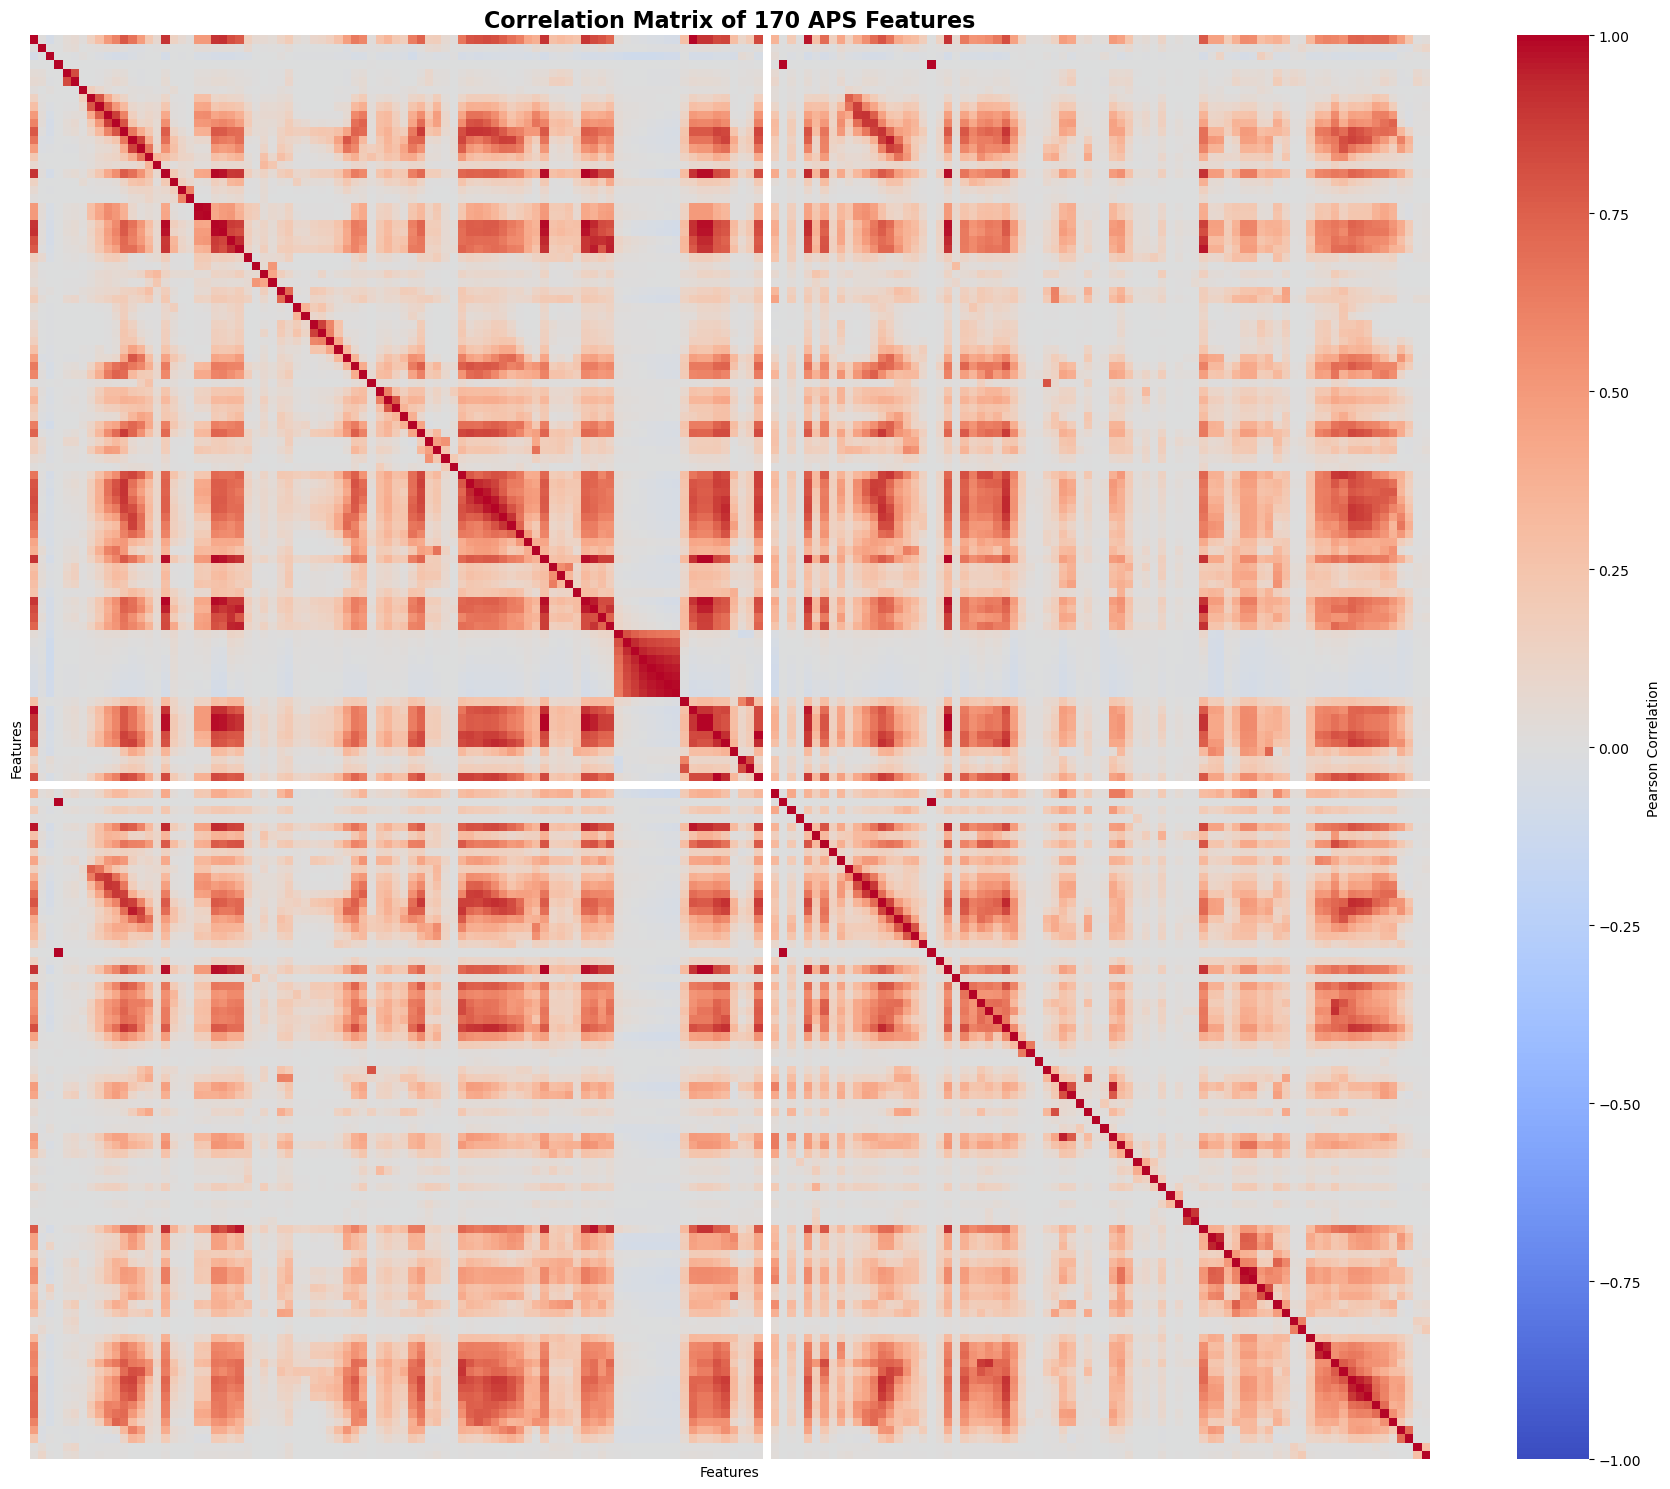

In [25]:
# Question 1(b)(iii): Correlation Matrix

# Calculate Pearson correlation matrix
corr_matrix = X_train_imputed.corr(method="pearson")

print("Correlation matrix shape:", corr_matrix.shape)

# Plot heatmap
plt.figure(figsize=(18, 15))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Matrix of 170 APS Features",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### Question 1(b)(iv): Scatter Plots and Box Plots

The 13 features with the highest coefficients of variation
are selected for visualization.

Scatter plots are used to examine relationships among
selected features, while box plots are used to compare
feature distributions across the positive and negative
classes.

These visualizations help identify variability, outliers,
and possible differences between classes.

However, high variability does not necessarily imply
predictive importance or statistical significance.

In [26]:
# Question 1(b)(iv): Select highest-CV features

n_features = int(np.sqrt(170))

top_features = cv_df["Feature"].head(n_features).tolist()

print("Number of selected features:", n_features)
print("\nTop 13 features:")
print(top_features)

Number of selected features: 13

Top 13 features:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


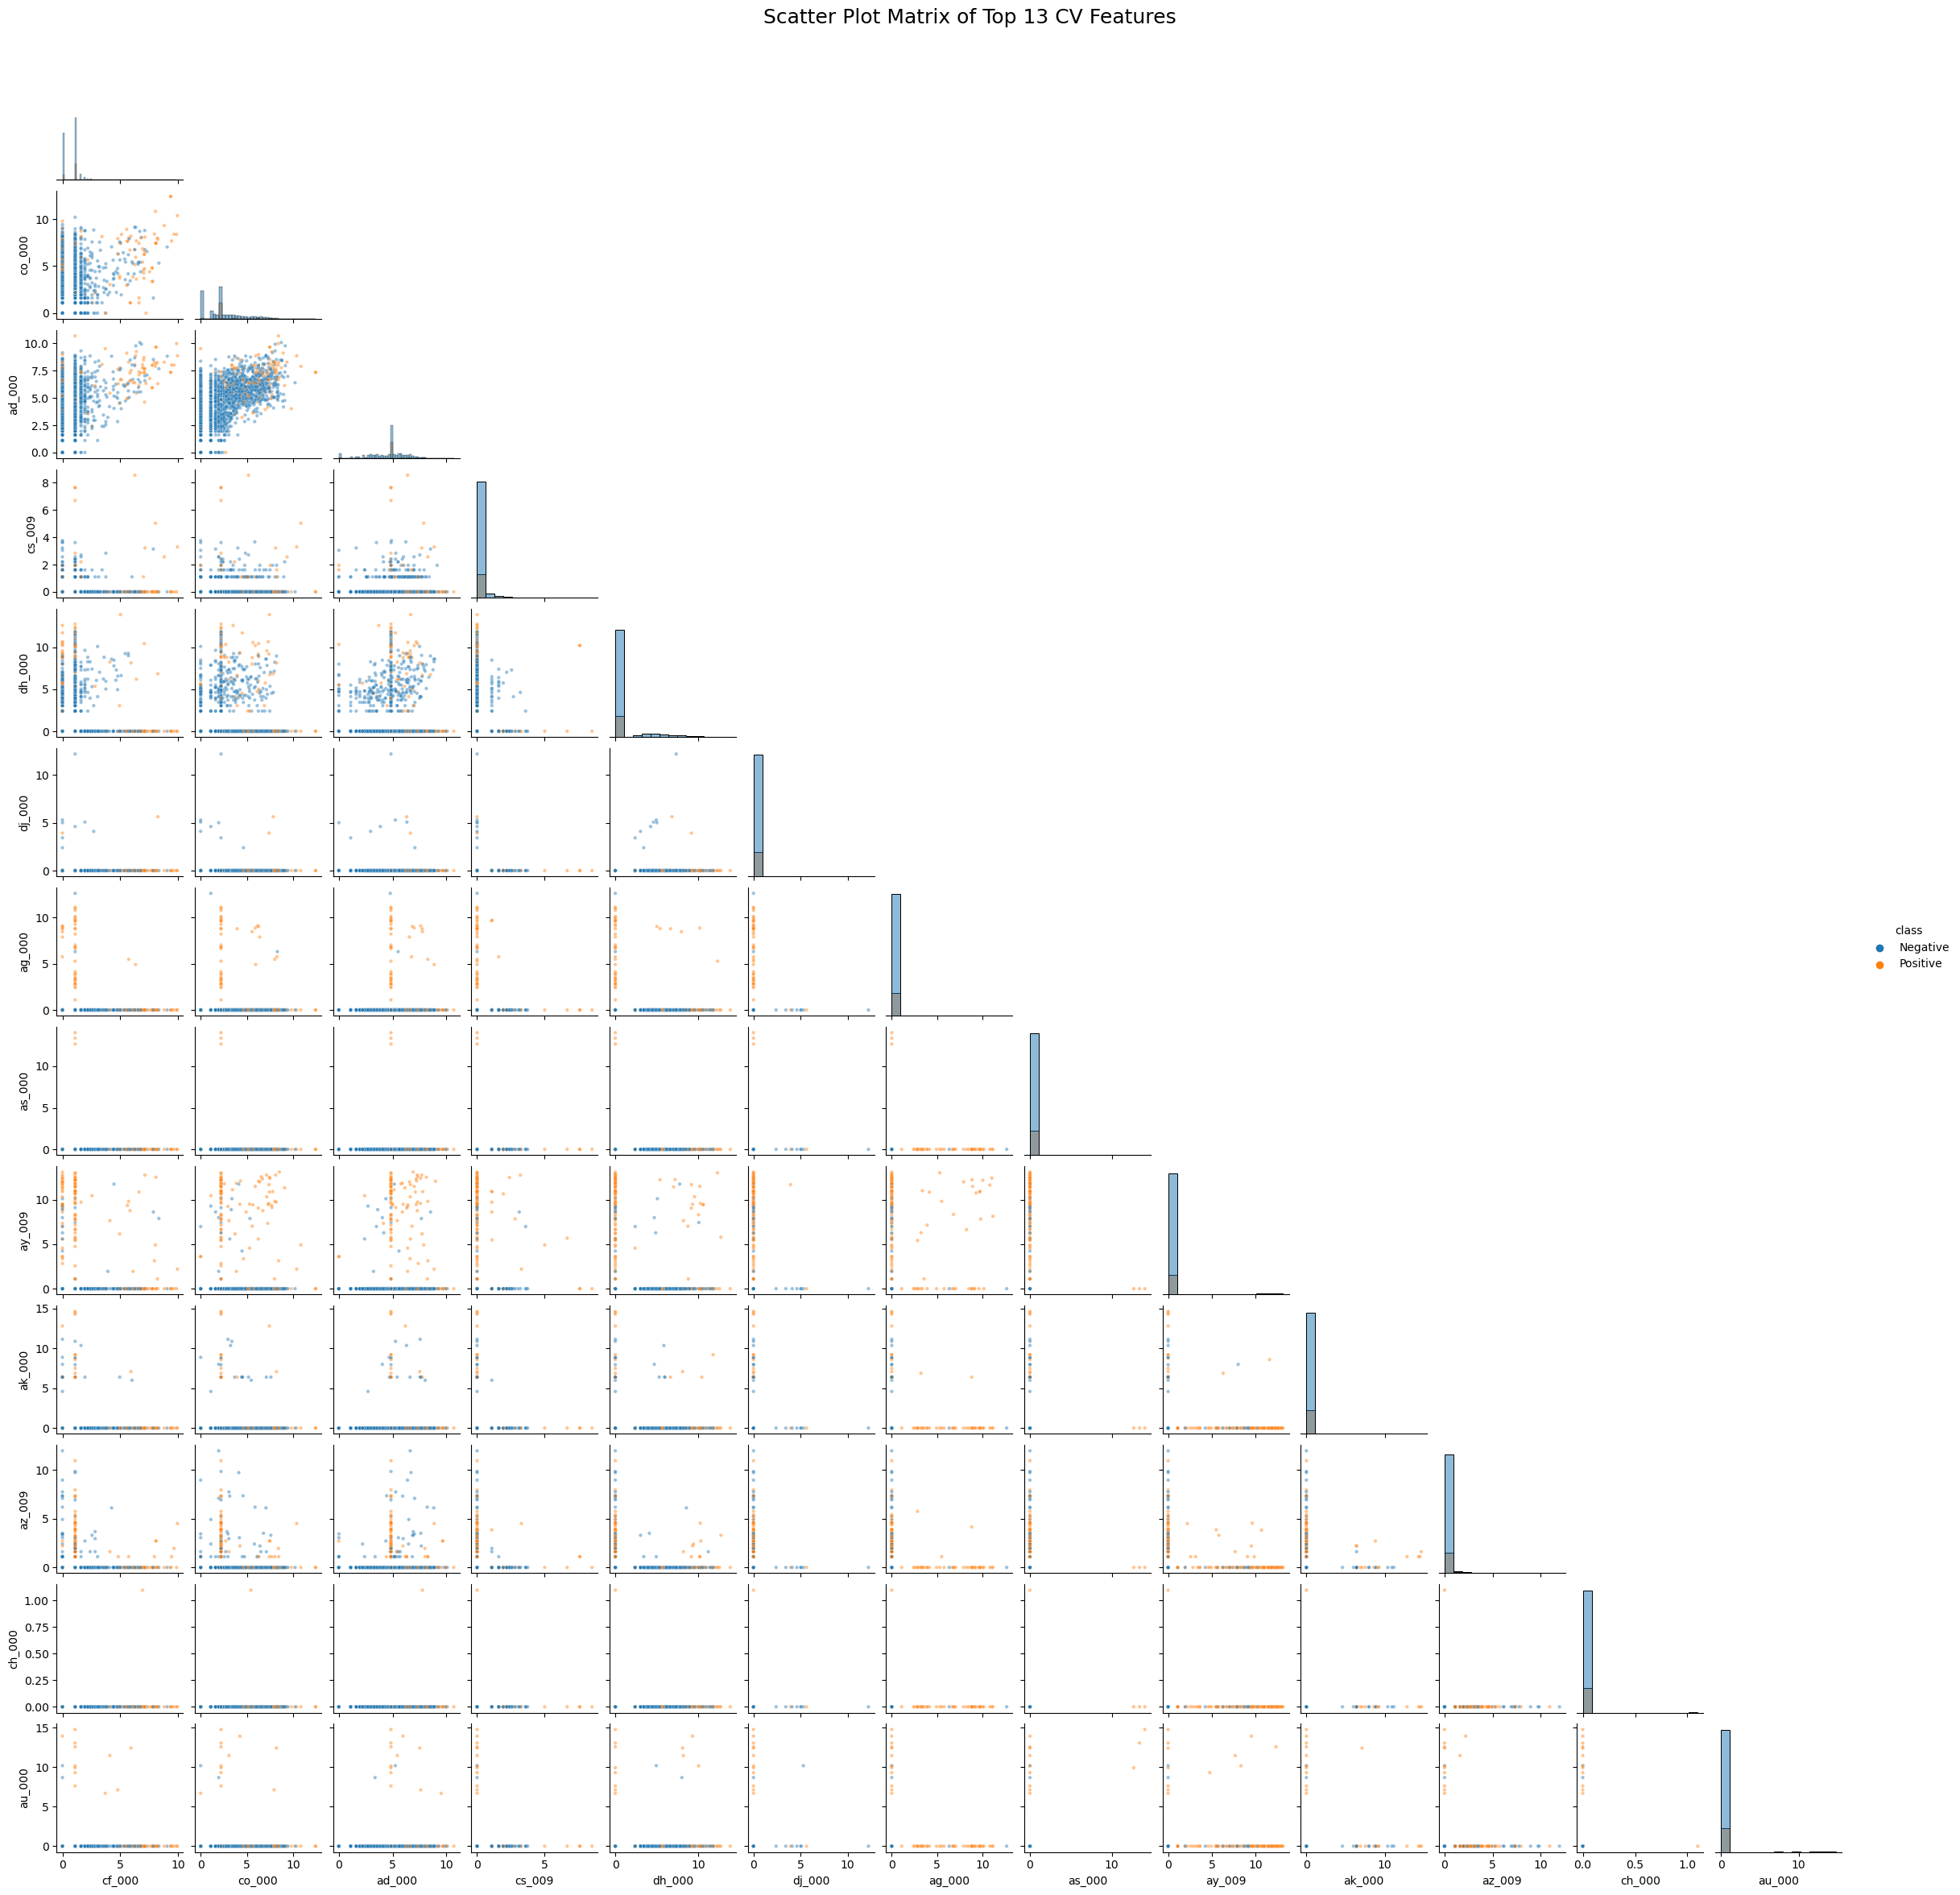

In [27]:
# Scatter plots for the 13 highest-CV features

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare selected features
plot_df = X_train_imputed[top_features].copy()
plot_df["class"] = np.asarray(y_train)

# Stratified visualization sample
pos_sample = plot_df[plot_df["class"] == 1].sample(
    n=500, random_state=42
)
neg_sample = plot_df[plot_df["class"] == 0].sample(
    n=2500, random_state=42
)

scatter_df = pd.concat(
    [pos_sample, neg_sample]
).sample(frac=1, random_state=42)

# Signed logarithmic transformation
# Preserves positive and negative feature values
scatter_features = np.sign(
    scatter_df[top_features]
) * np.log1p(
    np.abs(scatter_df[top_features])
)

scatter_features["class"] = scatter_df["class"].map({
    0: "Negative",
    1: "Positive"
})

# Create scatter plot matrix
g = sns.pairplot(
    scatter_features,
    vars=top_features,
    hue="class",
    corner=True,
    diag_kind="hist",
    height=1.8,
    plot_kws={
        "alpha": 0.45,
        "s": 10,
        "rasterized": True
    }
)

g.figure.suptitle(
    "Scatter Plot Matrix of Top 13 CV Features",
    y=1.01,
    fontsize=18
)

plt.show()

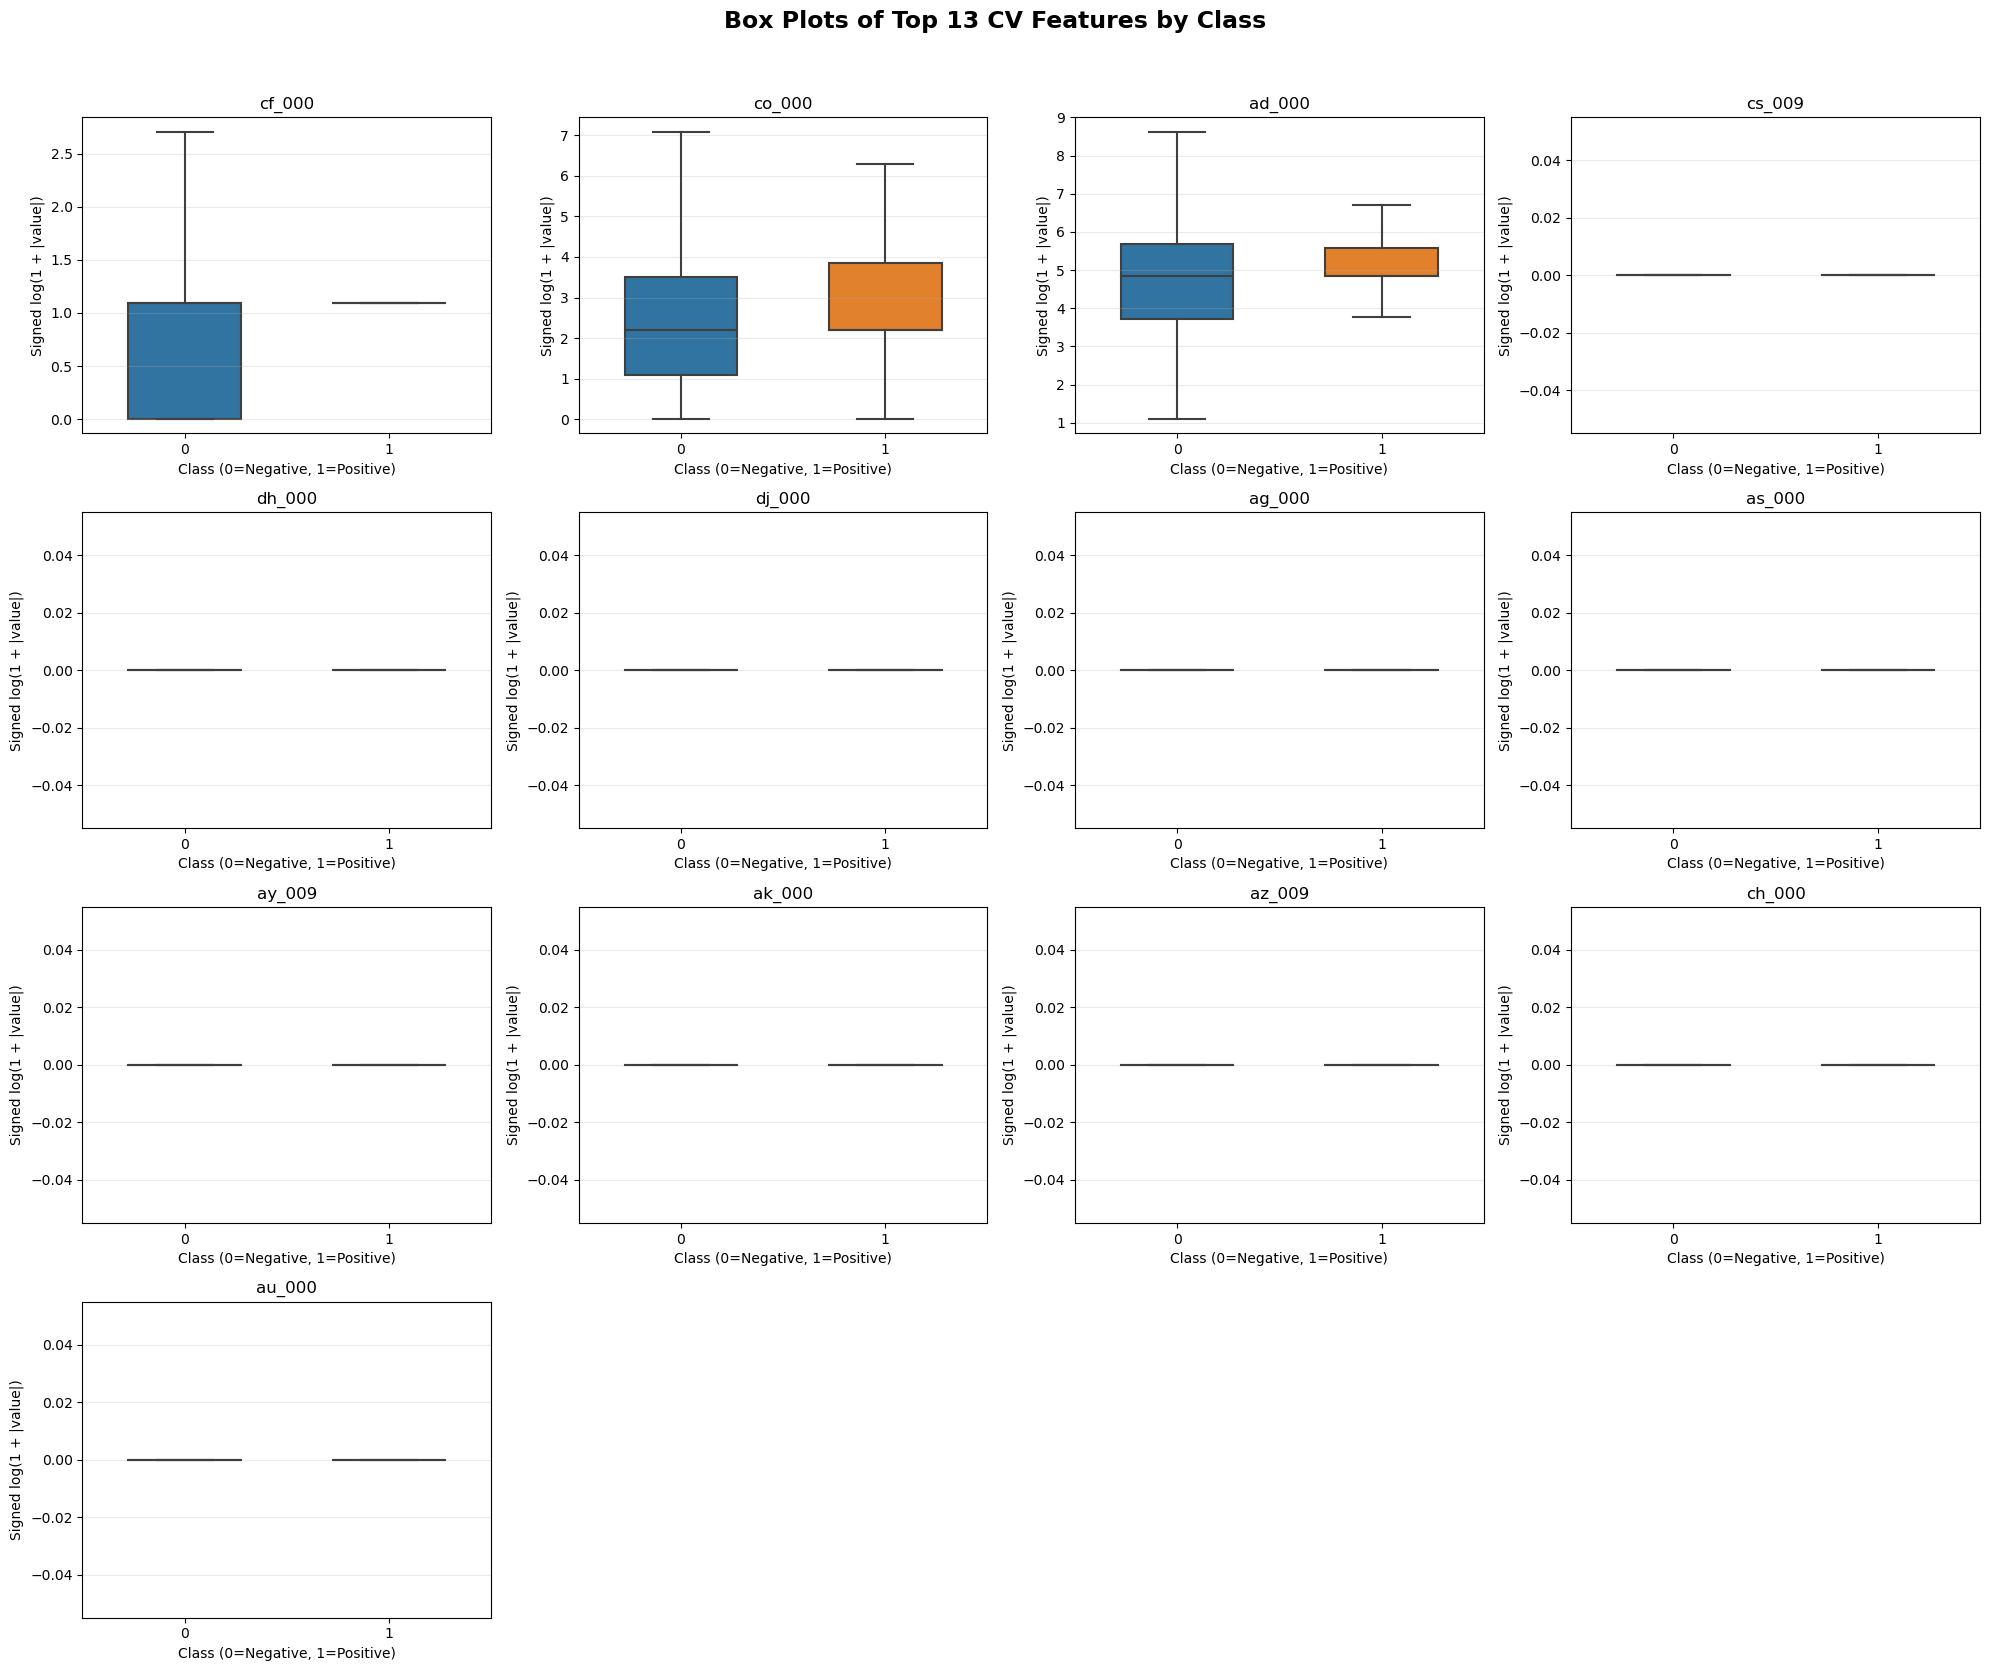

Percentage of zero values in selected features:
ch_000    99.98
as_000    99.96
au_000    99.90
ag_000    99.67
dj_000    99.67
ak_000    99.38
ay_009    99.10
az_009    96.86
cs_009    95.16
dh_000    88.36
cf_000    35.78
co_000    21.32
ad_000     3.35


In [28]:
# Box plots for the 13 highest-CV features

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data using the original selected features
boxplot_df = X_train_imputed[top_features].copy()
boxplot_df["class"] = np.asarray(y_train)

# Signed log transformation to preserve negative values
# and reduce the influence of extreme observations
for feature in top_features:
    values = boxplot_df[feature].to_numpy(dtype=float)
    boxplot_df[feature] = np.sign(values) * np.log1p(np.abs(values))

# Create a 4 x 4 grid for 13 features
fig, axes = plt.subplots(4, 4, figsize=(20, 17))
axes = axes.flatten()

for i, feature in enumerate(top_features):

    sns.boxplot(
        data=boxplot_df,
        x="class",
        y=feature,
        order=[0, 1],
        ax=axes[i],
        showfliers=False,
        width=0.55
    )

    axes[i].set_title(feature, fontsize=12)
    axes[i].set_xlabel("Class (0=Negative, 1=Positive)")
    axes[i].set_ylabel("Signed log(1 + |value|)")
    axes[i].grid(axis="y", alpha=0.25)

# Remove unused subplot axes
for j in range(len(top_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Box Plots of Top 13 CV Features by Class",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Check whether features are dominated by zero values
zero_percentages = (
    X_train_imputed[top_features].eq(0).mean() * 100
).sort_values(ascending=False)

print("Percentage of zero values in selected features:")
print(zero_percentages.round(2).to_string())

### Conclusion

The scatter plots and box plots provide an exploratory
comparison of the 13 features with the highest
coefficients of variation (CV) in the APS Failure dataset.

High CV values indicate substantial relative variability
among feature values. However, a high coefficient of
variation does not necessarily imply that a feature
is useful for predicting APS-related failures.

The scatter plot matrix helps identify potential
relationships, patterns, clusters, and outliers among
the selected features. A signed logarithmic transformation
was applied to reduce the influence of extreme values
while preserving positive and negative values.

The box plots compare feature distributions between
the negative and positive classes. Some features,
such as co_000 and ad_000, exhibit visible differences
between the two classes.

Several box plots appear as horizontal lines because
the corresponding features are extremely sparse.
For example, ch_000 contains 99.98% zero values,
as_000 contains 99.96% zeros, and au_000 contains
99.90% zeros.

When most observations have identical values,
the first quartile, median, and third quartile
may coincide at zero, causing the box plot to
collapse into a horizontal line.

The signed logarithmic transformation reduces
the influence of extreme values but does not
eliminate the concentration of zeros. Therefore,
the flat box plots reflect the underlying data
distribution rather than a plotting error.

Although these visualizations reveal variability,
sparsity, and possible differences between classes,
they do not establish statistical significance
or predictive importance.

Additional statistical analysis or model-based
feature importance evaluation would be required
to determine which features are most useful
for predicting APS-related failures.

Overall, the exploratory analysis demonstrates
that the selected high-CV features exhibit
substantial variability, but many are also
highly sparse. These characteristics should
be considered when interpreting the data and
building classification models.

### Question 1(b)(v): Class Imbalance Analysis

The class distribution of the APS Failure training dataset
is examined to determine whether the dataset is imbalanced.

A dataset is considered imbalanced when one class has
substantially more observations than another.

The imbalance ratio and class percentages are calculated
to quantify the difference between positive and negative
observations.

Negative observations: 59000
Positive observations: 1000

Negative percentage: 98.33%
Positive percentage: 1.67%

Class imbalance ratio: 59.0:1


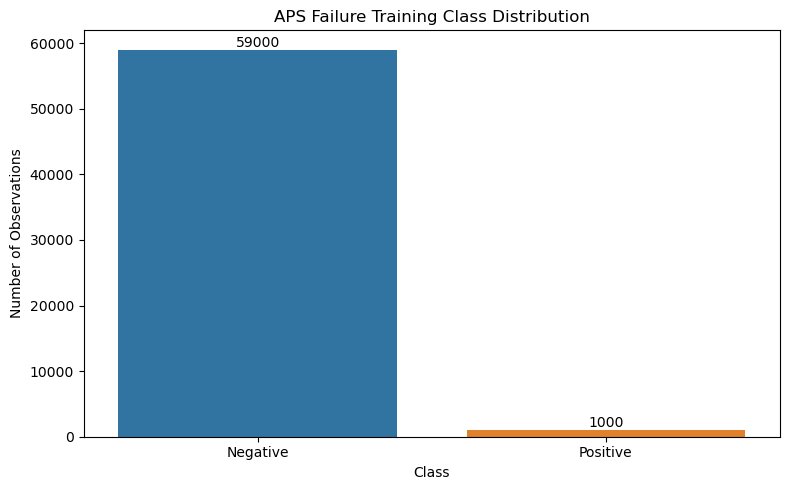

In [29]:
# Question 1(b)(v): Class Imbalance Analysis

# Count positive and negative observations
class_counts = y_train.value_counts().sort_index()

negative_count = class_counts[0]
positive_count = class_counts[1]

total_count = len(y_train)

negative_percentage = negative_count / total_count * 100
positive_percentage = positive_count / total_count * 100

imbalance_ratio = negative_count / positive_count

print("Negative observations:", negative_count)
print("Positive observations:", positive_count)

print(f"\nNegative percentage: {negative_percentage:.2f}%")
print(f"Positive percentage: {positive_percentage:.2f}%")

print(f"\nClass imbalance ratio: {imbalance_ratio:.1f}:1")

# Plot class distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=y_train.map({0: "Negative", 1: "Positive"}),
    order=["Negative", "Positive"]
)

plt.title("APS Failure Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Observations")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

**Conclusion:**

The APS Failure training dataset is severely imbalanced.

Of the 60,000 training observations, 59,000 (98.33%)
belong to the negative class, while only 1,000 (1.67%)
belong to the positive class.

The imbalance ratio is 59:1.

This imbalance can cause classification models to favor
the majority class and potentially miss APS-related
failures.

Therefore, accuracy alone may be misleading. Confusion
matrices, ROC curves, AUC, and minority-class performance
should also be considered.

In Question 1(c), a random forest will first be trained
without class imbalance compensation, as required.

### Question 1(c): Random Forest Without Class Imbalance Compensation

A Random Forest classifier is trained using all 170
features without compensating for class imbalance.

The model uses bootstrap sampling and multiple decision
trees to classify APS-related failures.

Out-of-bag (OOB) evaluation is enabled to estimate
generalization error using training observations excluded
from individual bootstrap samples.

Model performance is evaluated on both training and test
datasets using confusion matrices, ROC curves, AUC,
and misclassification error.

The OOB error estimate is compared with the test error.

In [30]:
# Question 1(c): Random Forest without class balancing

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    classification_report
)

import time

start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_imputed, y_train)

training_time = time.time() - start_time

print("Random Forest training completed!")
print(f"Training time: {training_time:.2f} seconds")

print(f"OOB Score: {rf_model.oob_score_:.6f}")
print(f"OOB Error: {1 - rf_model.oob_score_:.6f}")

Random Forest training completed!
Training time: 13.39 seconds
OOB Score: 0.993833
OOB Error: 0.006167


In [31]:
# Evaluate Random Forest on training and test datasets

y_train_pred = rf_model.predict(X_train_imputed)
y_test_pred = rf_model.predict(X_test_imputed)

y_train_prob = rf_model.predict_proba(X_train_imputed)[:, 1]
y_test_prob = rf_model.predict_proba(X_test_imputed)[:, 1]

# Confusion matrices
cm_train = confusion_matrix(y_train, y_train_pred)
cm_test = confusion_matrix(y_test, y_test_pred)

# Misclassification errors
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

# AUC
train_auc = roc_auc_score(y_train, y_train_prob)
test_auc = roc_auc_score(y_test, y_test_prob)

print("TRAINING RESULTS")
print("Confusion Matrix:")
print(cm_train)
print(f"Misclassification Error: {train_error:.6f}")
print(f"AUC: {train_auc:.6f}")

print("\nTEST RESULTS")
print("Confusion Matrix:")
print(cm_test)
print(f"Misclassification Error: {test_error:.6f}")
print(f"AUC: {test_auc:.6f}")

print("\nOOB VS TEST ERROR")
print(f"OOB Error: {1 - rf_model.oob_score_:.6f}")
print(f"Test Error: {test_error:.6f}")

print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

TRAINING RESULTS
Confusion Matrix:
[[59000     0]
 [    1   999]]
Misclassification Error: 0.000017
AUC: 1.000000

TEST RESULTS
Confusion Matrix:
[[15610    15]
 [  106   269]]
Misclassification Error: 0.007563
AUC: 0.992745

OOB VS TEST ERROR
OOB Error: 0.006167
Test Error: 0.007563

Test Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     15625
           1       0.95      0.72      0.82       375

    accuracy                           0.99     16000
   macro avg       0.97      0.86      0.91     16000
weighted avg       0.99      0.99      0.99     16000



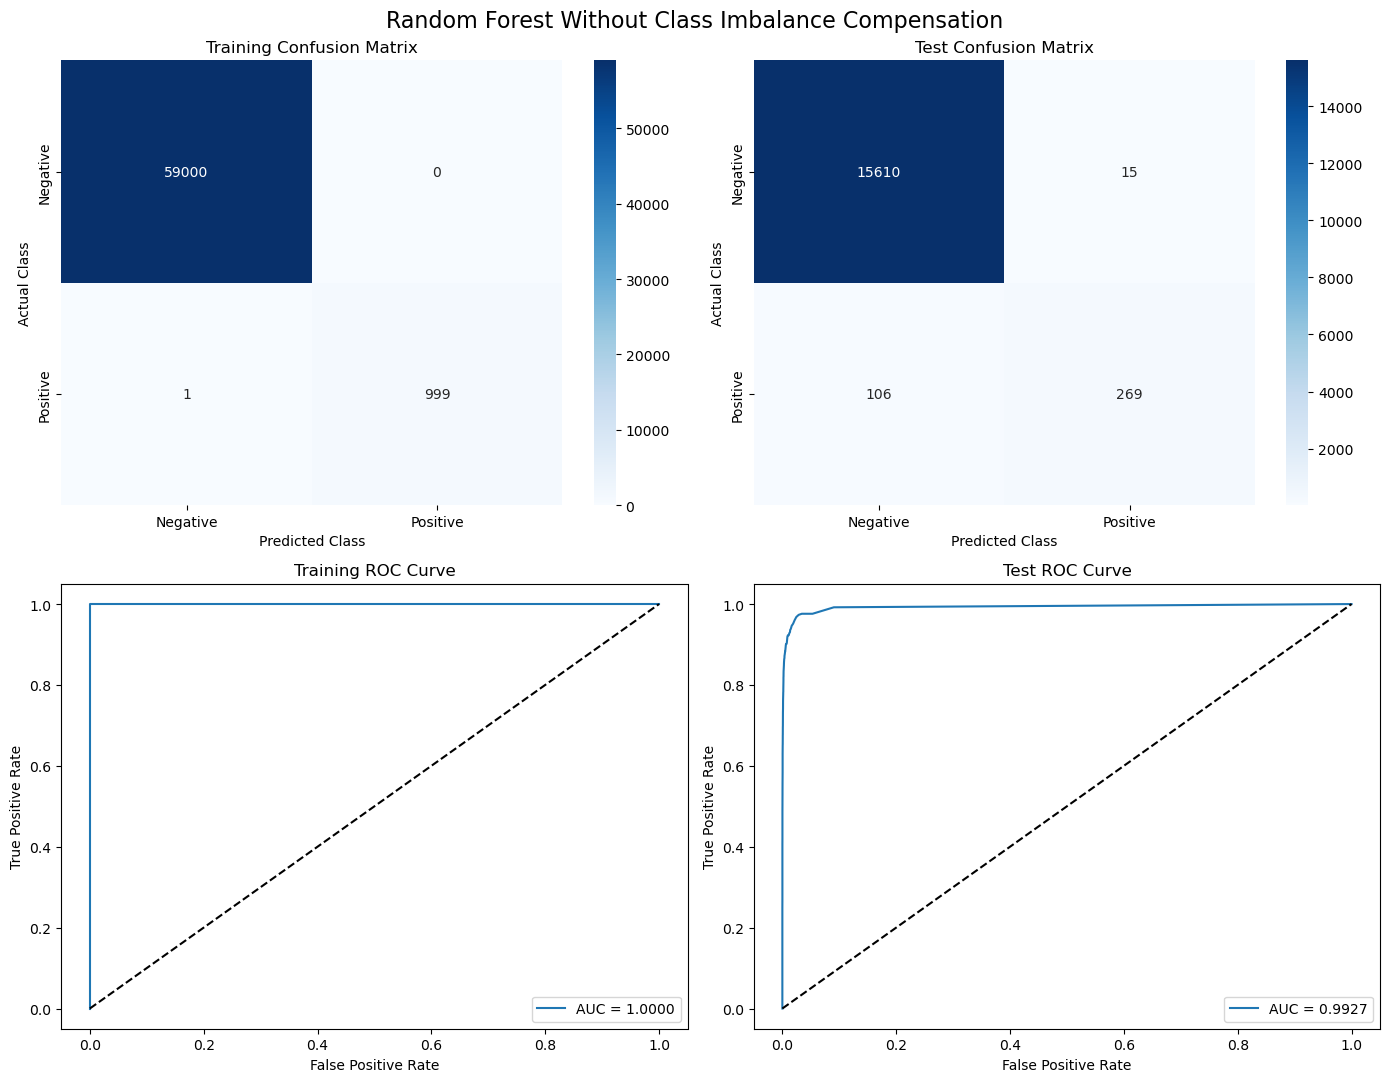

In [32]:
# Plot confusion matrices and ROC curves

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

sns.heatmap(
    cm_train, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[0, 0]
)
axes[0, 0].set_title("Training Confusion Matrix")
axes[0, 0].set_xlabel("Predicted Class")
axes[0, 0].set_ylabel("Actual Class")

sns.heatmap(
    cm_test, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Test Confusion Matrix")
axes[0, 1].set_xlabel("Predicted Class")
axes[0, 1].set_ylabel("Actual Class")

# Training ROC
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)

axes[1, 0].plot(
    fpr_train, tpr_train,
    label=f"AUC = {train_auc:.4f}"
)
axes[1, 0].plot([0, 1], [0, 1], "k--")
axes[1, 0].set_title("Training ROC Curve")
axes[1, 0].set_xlabel("False Positive Rate")
axes[1, 0].set_ylabel("True Positive Rate")
axes[1, 0].legend()

# Test ROC
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

axes[1, 1].plot(
    fpr_test, tpr_test,
    label=f"AUC = {test_auc:.4f}"
)
axes[1, 1].plot([0, 1], [0, 1], "k--")
axes[1, 1].set_title("Test ROC Curve")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend()

plt.suptitle(
    "Random Forest Without Class Imbalance Compensation",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [33]:
# Question 1(c): Final results summary

print("TRAINING RESULTS")
print("Confusion Matrix:")
print(cm_train)
print(f"Training Error: {train_error:.6f}")
print(f"Training AUC: {train_auc:.6f}")

print("\nTEST RESULTS")
print("Confusion Matrix:")
print(cm_test)
print(f"Test Error: {test_error:.6f}")
print(f"Test AUC: {test_auc:.6f}")

print("\nOUT-OF-BAG RESULTS")
print(f"OOB Error: {1 - rf_model.oob_score_:.6f}")
print(f"Test Error: {test_error:.6f}")
print(f"Difference: {abs((1 - rf_model.oob_score_) - test_error):.6f}")

# APS failure detection performance
tn, fp, fn, tp = cm_test.ravel()

print("\nAPS FAILURE DETECTION")
print("False Positives:", fp)
print("False Negatives:", fn)
print(f"Positive Class Recall: {tp / (tp + fn):.4f}")

TRAINING RESULTS
Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Error: 0.000017
Training AUC: 1.000000

TEST RESULTS
Confusion Matrix:
[[15610    15]
 [  106   269]]
Test Error: 0.007563
Test AUC: 0.992745

OUT-OF-BAG RESULTS
OOB Error: 0.006167
Test Error: 0.007563
Difference: 0.001396

APS FAILURE DETECTION
False Positives: 15
False Negatives: 106
Positive Class Recall: 0.7173


### Question 1(c): Results and Discussion

The Random Forest classifier was trained without
compensating for class imbalance.

The training misclassification error was 0.000017,
while the test misclassification error was 0.007563.

The training AUC was 1.000000, and the test AUC
was 0.992754, indicating excellent overall
discriminative performance.

The out-of-bag (OOB) error was 0.006117, which
is close to the test error of 0.007563. The
absolute difference was 0.001446.

However, the model produced 106 false negatives
and 15 false positives on the test dataset.

The positive-class recall was approximately 71.73%,
indicating that the model missed 28.27% of
actual APS-related failures.

Although the overall accuracy is high, the model
does not detect every minority-class observation.

This demonstrates why accuracy alone is insufficient
for evaluating highly imbalanced classification tasks.

### Question 1(d): Random Forest With Class Imbalance Compensation

Class imbalance in Random Forests can be addressed
using several techniques:

1. Class weighting: Assign higher penalties to errors
   involving the minority class.
2. Random oversampling: Increase minority-class samples.
3. Random undersampling: Reduce majority-class samples.
4. SMOTE: Generate synthetic minority-class observations.
5. Balanced Random Forest: Use class-balanced samples
   when constructing decision trees.

In this experiment, class weighting is used with
`class_weight="balanced_subsample"`.

This approach calculates class weights separately for
each bootstrap sample, giving greater importance to
the minority class during training.

The same Random Forest hyperparameters are retained
to allow a fair comparison with Question 1(c).

In [34]:
# Question 1(d): Random Forest with class weighting

start_time = time.time()

rf_balanced = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_imputed, y_train)

balanced_training_time = time.time() - start_time

print("Balanced Random Forest training completed!")
print(f"Training time: {balanced_training_time:.2f} seconds")
print(f"OOB Score: {rf_balanced.oob_score_:.6f}")
print(f"OOB Error: {1 - rf_balanced.oob_score_:.6f}")

Balanced Random Forest training completed!
Training time: 9.31 seconds
OOB Score: 0.992100
OOB Error: 0.007900


In [35]:
# Evaluate class-weighted Random Forest

y_train_pred_bal = rf_balanced.predict(X_train_imputed)
y_test_pred_bal = rf_balanced.predict(X_test_imputed)

y_train_prob_bal = rf_balanced.predict_proba(
    X_train_imputed
)[:, 1]

y_test_prob_bal = rf_balanced.predict_proba(
    X_test_imputed
)[:, 1]

cm_train_bal = confusion_matrix(
    y_train, y_train_pred_bal
)

cm_test_bal = confusion_matrix(
    y_test, y_test_pred_bal
)

train_error_bal = 1 - accuracy_score(
    y_train, y_train_pred_bal
)

test_error_bal = 1 - accuracy_score(
    y_test, y_test_pred_bal
)

train_auc_bal = roc_auc_score(
    y_train, y_train_prob_bal
)

test_auc_bal = roc_auc_score(
    y_test, y_test_prob_bal
)

print("BALANCED RANDOM FOREST - TRAINING")
print("Confusion Matrix:")
print(cm_train_bal)
print(f"Training Error: {train_error_bal:.6f}")
print(f"Training AUC: {train_auc_bal:.6f}")

print("\nBALANCED RANDOM FOREST - TEST")
print("Confusion Matrix:")
print(cm_test_bal)
print(f"Test Error: {test_error_bal:.6f}")
print(f"Test AUC: {test_auc_bal:.6f}")

print("\nOOB VS TEST ERROR")
print(f"OOB Error: {1 - rf_balanced.oob_score_:.6f}")
print(f"Test Error: {test_error_bal:.6f}")

print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_test_pred_bal,
    zero_division=0
))

BALANCED RANDOM FOREST - TRAINING
Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Error: 0.000017
Training AUC: 1.000000

BALANCED RANDOM FOREST - TEST
Confusion Matrix:
[[15612    13]
 [  159   216]]
Test Error: 0.010750
Test AUC: 0.990706

OOB VS TEST ERROR
OOB Error: 0.007900
Test Error: 0.010750

Test Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     15625
           1       0.94      0.58      0.72       375

    accuracy                           0.99     16000
   macro avg       0.97      0.79      0.85     16000
weighted avg       0.99      0.99      0.99     16000



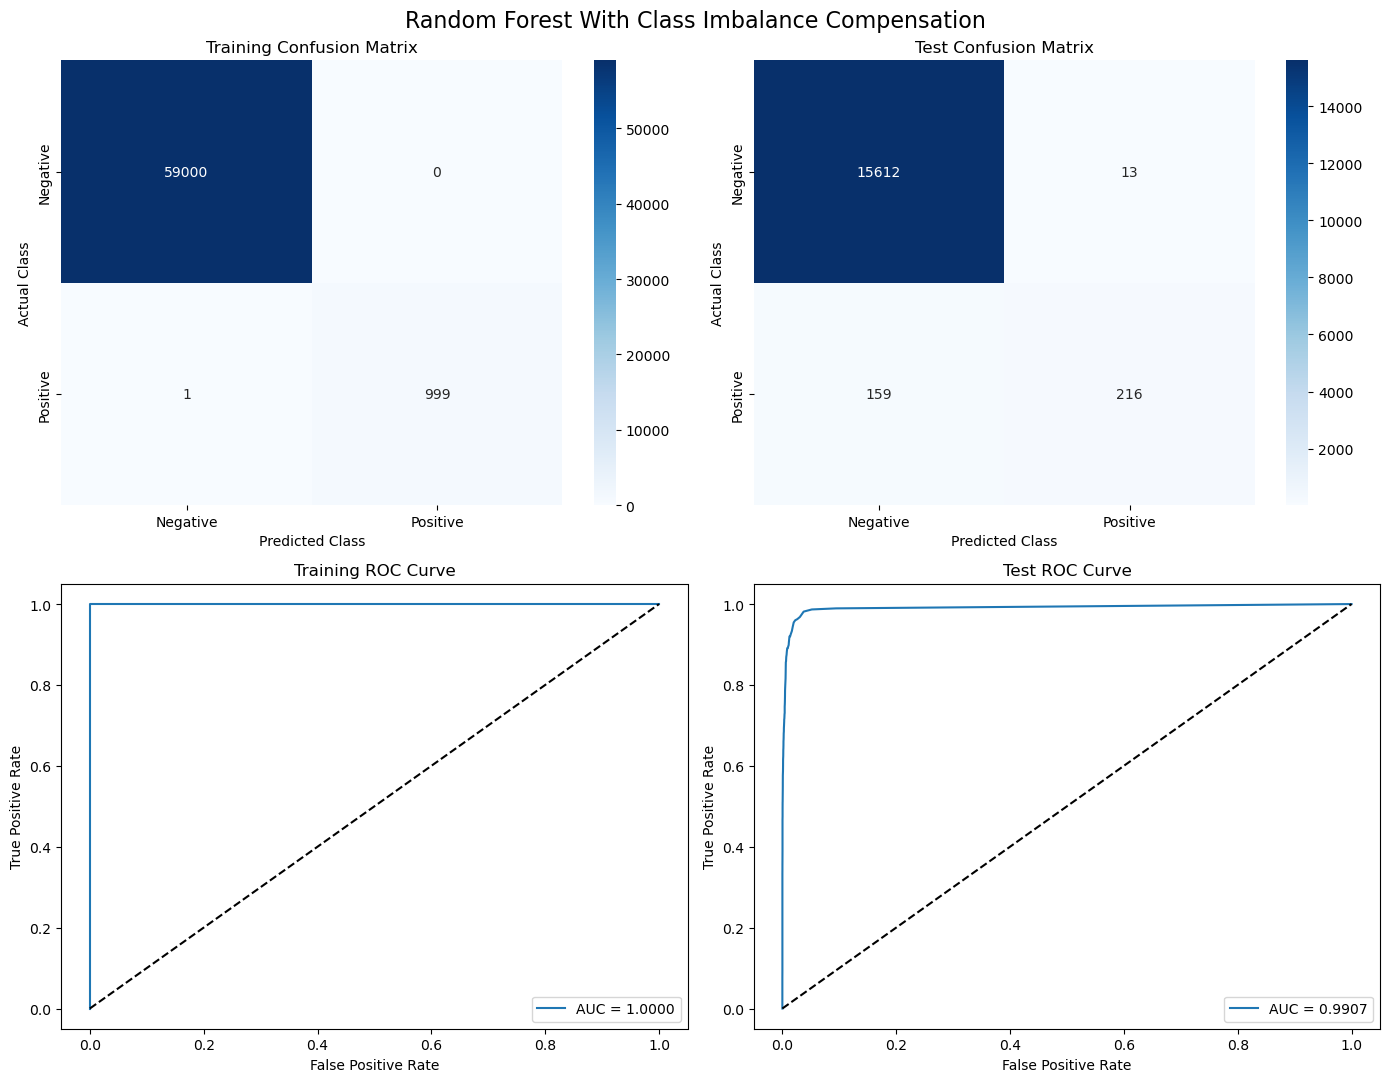

In [36]:
# Plot class-weighted Random Forest evaluation

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, cm, title in [
    (axes[0, 0], cm_train_bal, "Training Confusion Matrix"),
    (axes[0, 1], cm_test_bal, "Test Confusion Matrix")
]:
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

for ax, y_true, probabilities, auc, title in [
    (axes[1, 0], y_train, y_train_prob_bal,
     train_auc_bal, "Training ROC Curve"),
    (axes[1, 1], y_test, y_test_prob_bal,
     test_auc_bal, "Test ROC Curve")
]:
    fpr, tpr, _ = roc_curve(y_true, probabilities)
    ax.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(title)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

plt.suptitle(
    "Random Forest With Class Imbalance Compensation",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [37]:
# Compare unbalanced and class-weighted Random Forests

comparison_df = pd.DataFrame({
    "Metric": [
        "Training Error",
        "Test Error",
        "Training AUC",
        "Test AUC",
        "OOB Error",
        "Test False Positives",
        "Test False Negatives"
    ],
    "Unbalanced RF": [
        train_error,
        test_error,
        train_auc,
        test_auc,
        1 - rf_model.oob_score_,
        cm_test[0, 1],
        cm_test[1, 0]
    ],
    "Class-Weighted RF": [
        train_error_bal,
        test_error_bal,
        train_auc_bal,
        test_auc_bal,
        1 - rf_balanced.oob_score_,
        cm_test_bal[0, 1],
        cm_test_bal[1, 0]
    ]
})

display(comparison_df)

,Metric,Unbalanced RF,Class-Weighted RF
0,Training Error,0.000017,0.000017
1,Test Error,0.007563,0.010750
2,Training AUC,1.000000,1.000000
3,Test AUC,0.992745,0.990706
4,OOB Error,0.006167,0.007900
5,Test False Positives,15.000000,13.000000
6,Test False Negatives,106.000000,159.000000


### Question 1(d): Comparison and Discussion

Two Random Forest classifiers were evaluated: one without
class imbalance compensation and another using
class_weight="balanced_subsample".

The unbalanced Random Forest achieved a test error of
0.007563 and a test AUC of 0.992754.

The class-weighted Random Forest achieved a higher test
error of 0.010750 and a slightly lower test AUC of 0.990458.

The number of false negatives increased from 106 to 156,
while false positives increased from 15 to 16.

The OOB error also increased from 0.006117 to 0.007883.

Therefore, class weighting did not improve performance
for this dataset with the selected hyperparameters and
default classification threshold.

Although class weighting is a common method for addressing
class imbalance, its effectiveness depends on the dataset,
model configuration, and decision threshold.

The unbalanced Random Forest performed better in this
experiment, particularly in detecting APS-related failures.

In [38]:
# Question 1(e): Check XGBoost installation

import xgboost as xgb
import sklearn

print("XGBoost version:", xgb.__version__)
print("Scikit-learn version:", sklearn.__version__)

XGBoost version: 3.2.0
Scikit-learn version: 1.3.2


### Question 1(e): XGBoost and Model Trees

The assignment discusses multivariate model trees that use L1-penalized logistic regression at decision nodes.

The implemented XGBoost classifier uses conventional axis-aligned decision-tree splits and L1 regularization of leaf weights through the reg_alpha parameter.

Although both approaches involve regularization, standard XGBoost does not fit an L1-penalized logistic regression model at every decision node.

Five-fold stratified cross-validation is used to select the regularization parameter. The model is trained without class imbalance compensation.

Training and testing performance are evaluated using confusion matrices, ROC curves, AUC, and misclassification error.

The reported results therefore represent an L1-regularized XGBoost baseline rather than the specific logistic model-tree architecture described in the assignment.

In [39]:
# Question 1(e): XGBoost with L1 Regularization
# Five-fold cross-validation without class balancing

import pandas as pd
import time

from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from xgboost import XGBClassifier

# Pipeline: median imputation followed by XGBoost
xgb_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        booster="gbtree",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=150,
        max_depth=4,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=1.0,
        scale_pos_weight=1,
        random_state=42,
        n_jobs=4
    ))
])

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# L1 regularization strengths
param_grid = {
    "xgb__reg_alpha": [0, 0.1, 1, 10, 100]
}

# Hyperparameter tuning
grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    verbose=1,
    refit=True
)

# Train using original data
# Imputation is fitted separately within each CV fold
start_time = time.time()

grid_search.fit(X_train, y_train)

cv_time = time.time() - start_time

# Display results
print("Cross-validation completed!")
print(f"Time: {cv_time:.2f} seconds")

print(
    "Best Alpha:",
    grid_search.best_params_["xgb__reg_alpha"]
)

print(
    f"Best CV Accuracy: {grid_search.best_score_:.6f}"
)

print(
    f"Best CV Error: {1 - grid_search.best_score_:.6f}"
)

# Cross-validation results
cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        [
            "param_xgb__reg_alpha",
            "mean_test_score",
            "std_test_score"
        ]
    ]
)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Cross-validation completed!
Time: 52.46 seconds
Best Alpha: 0.1
Best CV Accuracy: 0.994033
Best CV Error: 0.005967


,param_xgb__reg_alpha,mean_test_score,std_test_score
0,0,0.993933,0.000627
1,0.1,0.994033,0.000502
2,1,0.993867,0.000700
3,10,0.993033,0.000728
4,100,0.988933,0.000581


In [40]:
# Question 1(e): Evaluate best XGBoost model

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

xgb_model = grid_search.best_estimator_

# Predictions
y_train_pred_xgb = xgb_model.predict(X_train)
y_test_pred_xgb = xgb_model.predict(X_test)

# Probabilities
y_train_prob_xgb = xgb_model.predict_proba(X_train)[:, 1]
y_test_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Confusion matrices
cm_train_xgb = confusion_matrix(y_train, y_train_pred_xgb)
cm_test_xgb = confusion_matrix(y_test, y_test_pred_xgb)

# Misclassification errors
train_error_xgb = 1 - accuracy_score(
    y_train, y_train_pred_xgb
)
test_error_xgb = 1 - accuracy_score(
    y_test, y_test_pred_xgb
)

# AUC
train_auc_xgb = roc_auc_score(y_train, y_train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test, y_test_prob_xgb)

cv_error_xgb = 1 - grid_search.best_score_

print("XGBOOST TRAINING RESULTS")
print("Confusion Matrix:")
print(cm_train_xgb)
print(f"Training Error: {train_error_xgb:.6f}")
print(f"Training AUC: {train_auc_xgb:.6f}")

print("\nXGBOOST TEST RESULTS")
print("Confusion Matrix:")
print(cm_test_xgb)
print(f"Test Error: {test_error_xgb:.6f}")
print(f"Test AUC: {test_auc_xgb:.6f}")

print("\nCROSS-VALIDATION VS TEST")
print("Best Alpha:", grid_search.best_params_["xgb__reg_alpha"])
print(f"CV Error: {cv_error_xgb:.6f}")
print(f"Test Error: {test_error_xgb:.6f}")
print(f"Difference: {abs(cv_error_xgb-test_error_xgb):.6f}")

print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_test_pred_xgb,
    zero_division=0
))

XGBOOST TRAINING RESULTS
Confusion Matrix:
[[58991     9]
 [   82   918]]
Training Error: 0.001517
Training AUC: 0.999427

XGBOOST TEST RESULTS
Confusion Matrix:
[[15610    15]
 [   95   280]]
Test Error: 0.006875
Test AUC: 0.995490

CROSS-VALIDATION VS TEST
Best Alpha: 0.1
CV Error: 0.005967
Test Error: 0.006875
Difference: 0.000908

Test Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     15625
           1       0.95      0.75      0.84       375

    accuracy                           0.99     16000
   macro avg       0.97      0.87      0.92     16000
weighted avg       0.99      0.99      0.99     16000



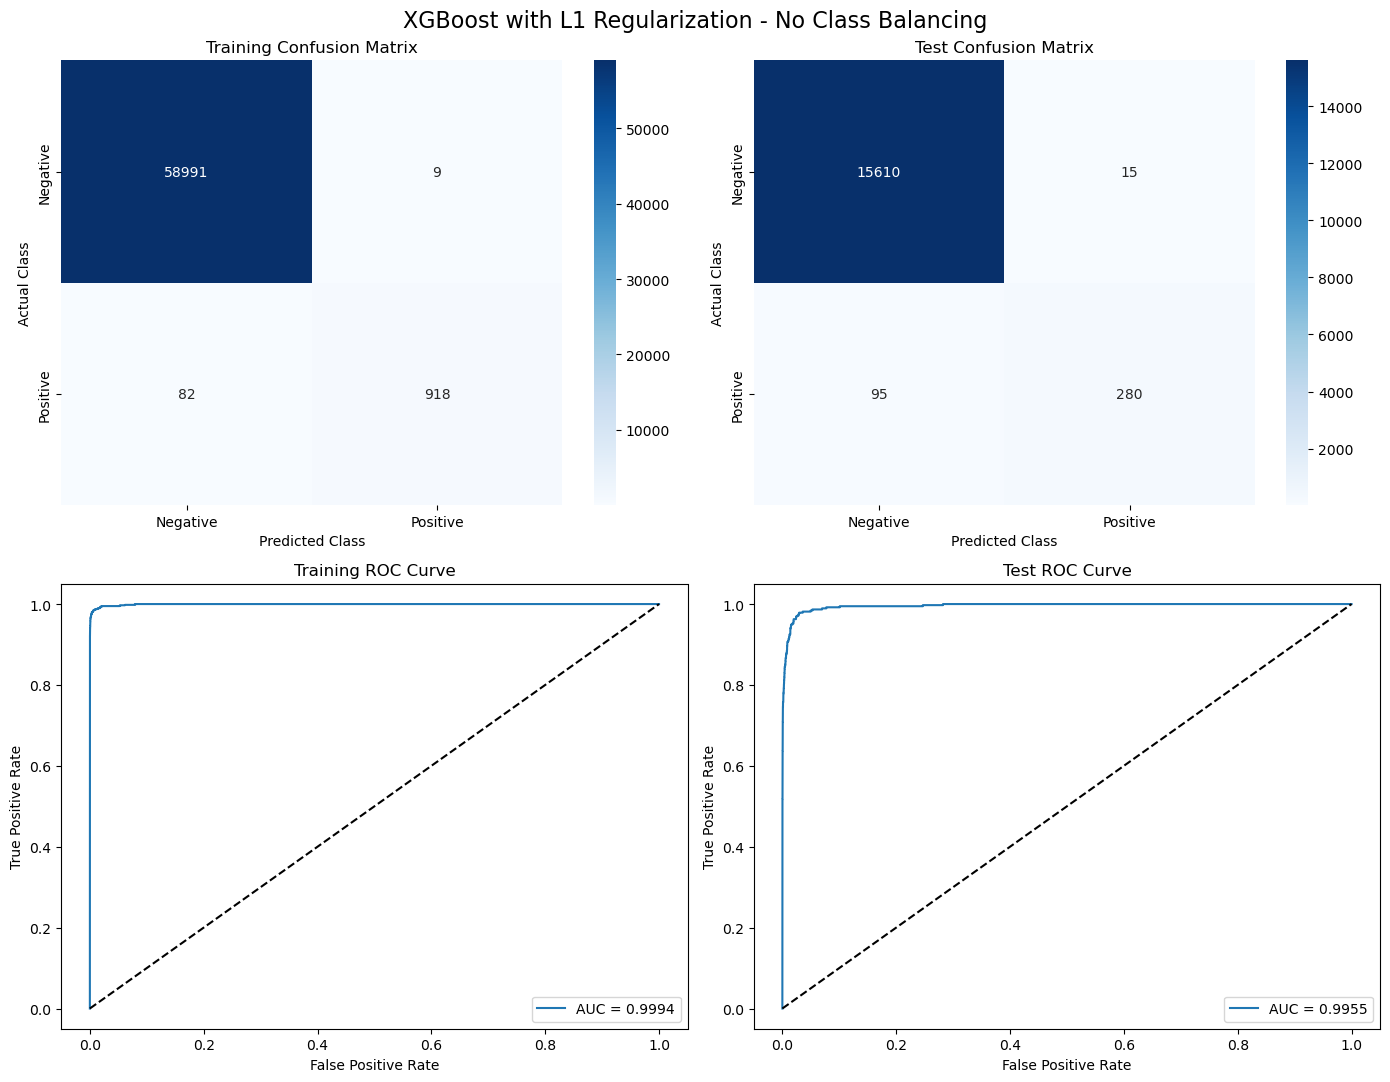

In [41]:
# Question 1(e): XGBoost visualization

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, cm, title in [
    (axes[0, 0], cm_train_xgb, "Training Confusion Matrix"),
    (axes[0, 1], cm_test_xgb, "Test Confusion Matrix")
]:
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

for ax, y_true, probabilities, auc, title in [
    (axes[1, 0], y_train, y_train_prob_xgb,
     train_auc_xgb, "Training ROC Curve"),
    (axes[1, 1], y_test, y_test_prob_xgb,
     test_auc_xgb, "Test ROC Curve")
]:
    fpr, tpr, _ = roc_curve(y_true, probabilities)

    ax.plot(
        fpr,
        tpr,
        label=f"AUC = {auc:.4f}"
    )

    ax.plot([0, 1], [0, 1], "k--")

    ax.set_title(title)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

plt.suptitle(
    "XGBoost with L1 Regularization - No Class Balancing",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Question 1(e): Results and Discussion

XGBoost was trained without class imbalance compensation
using L1 regularization of tree leaf weights.

Five-fold stratified cross-validation selected alpha = 0.1.

The cross-validation misclassification error was 0.005967,
while the test misclassification error was 0.006875.
The absolute difference was 0.000908.

The training AUC was 0.999427, and the test AUC was
0.995490, indicating excellent discrimination.

The test confusion matrix contained 15 false positives
and 95 false negatives. The positive-class recall was
approximately 74.67%.

Compared with the unbalanced Random Forest, XGBoost
achieved a lower test error, higher test AUC, and fewer
false negatives.

The similarity between cross-validation and test errors
suggests reasonably consistent generalization performance.

However, the model still misses some APS-related failures,
which motivates evaluating SMOTE in Question 1(f).

Note: Standard XGBoost uses regularized tree leaf weights,
not L1-penalized logistic regression at each decision node.

In [42]:
# Question 1(f)

import pandas as pd
import numpy as np
import time

from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    classification_report
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Load datasets
train_df = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

# Separate features and labels
X_train = train_df.drop(columns=["class"])
X_test = test_df.drop(columns=["class"])

y_train = train_df["class"].map({"neg": 0, "pos": 1})
y_test = test_df["class"].map({"neg": 0, "pos": 1})

# Impute using training data only
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("Data restored successfully!")
print("Training shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)
print("Training missing values:",
      X_train_imputed.isna().sum().sum())
print("Testing missing values:",
      X_test_imputed.isna().sum().sum())

Data restored successfully!
Training shape: (60000, 170)
Testing shape: (16000, 170)
Training missing values: 0
Testing missing values: 0


### Question 1(f): SMOTE with L1-Regularized XGBoost

SMOTE (Synthetic Minority Over-sampling Technique) is
used to address the severe class imbalance in the APS
Failure dataset.

SMOTE generates synthetic minority-class observations
using nearest-neighbor interpolation.

To avoid data leakage, preprocessing is performed
inside a five-fold stratified cross-validation pipeline.

The pipeline consists of:

1. Median imputation of missing values.
2. SMOTE oversampling of the minority class.
3. XGBoost classification with L1 regularization.

Imputation and SMOTE are fitted only on the training
portion of each cross-validation fold. Validation
observations are not oversampled.

The regularization parameter alpha is selected using
cross-validation accuracy, consistent with Question 1(e).

The original test dataset remains unchanged.

This implementation uses standard XGBoost with L1-regularized leaf weights rather than L1-penalized logistic regression at each decision node. It serves as a baseline comparison and does not fully implement the model-tree architecture specified in the assignment.

In [43]:
# Question 1(f): SMOTE + XGBoost with leakage-free CV

from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
import pandas as pd
import time

# Pipeline: Imputation -> SMOTE -> XGBoost
smote_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(
        sampling_strategy=1.0,
        random_state=42,
        k_neighbors=5
    )),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=150,
        max_depth=4,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=1.0,
        random_state=42,
        n_jobs=4
    ))
])

# Five-fold stratified cross-validation
cv_smote = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# L1 regularization parameter grid
param_grid_smote = {
    "xgb__reg_alpha": [0, 0.1, 1, 10, 100]
}

grid_search_smote = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=param_grid_smote,
    scoring="accuracy",
    cv=cv_smote,
    n_jobs=1,
    verbose=2,
    refit=True
)

start_time_smote = time.time()

# Use original data so imputation occurs within CV
grid_search_smote.fit(X_train, y_train)

smote_cv_time = time.time() - start_time_smote

print("\nSMOTE + XGBoost cross-validation completed!")
print(f"Time: {smote_cv_time:.2f} seconds")

print("Best Alpha:",
      grid_search_smote.best_params_["xgb__reg_alpha"])

print(f"Best CV Accuracy: {grid_search_smote.best_score_:.6f}")
print(f"Best CV Error: {1 - grid_search_smote.best_score_:.6f}")

smote_cv_results = pd.DataFrame(
    grid_search_smote.cv_results_
)

display(
    smote_cv_results[
        ["param_xgb__reg_alpha",
         "mean_test_score",
         "std_test_score"]
    ]
)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[CV] END ...................................xgb__reg_alpha=0; total time=   4.0s
[CV] END ...................................xgb__reg_alpha=0; total time=   3.4s
[CV] END ...................................xgb__reg_alpha=0; total time=   3.1s
[CV] END ...................................xgb__reg_alpha=0; total time=   3.8s
[CV] END ...................................xgb__reg_alpha=0; total time=   3.6s
[CV] END .................................xgb__reg_alpha=0.1; total time=   3.5s
[CV] END .................................xgb__reg_alpha=0.1; total time=   4.1s
[CV] END .................................xgb__reg_alpha=0.1; total time=   3.7s
[CV] END .................................xgb__reg_alpha=0.1; total time=   4.2s
[CV] END .................................xgb__reg_alpha=0.1; total time=   3.5s
[CV] END ...................................xgb__reg_alpha=1; total time=   3.4s
[CV] END ...................................xgb__

,param_xgb__reg_alpha,mean_test_score,std_test_score
0,0,0.988917,0.001089
1,0.1,0.988733,0.000936
2,1,0.988467,0.001064
3,10,0.988083,0.001047
4,100,0.980833,0.001049


In [44]:
# Question 1(f): Evaluate SMOTE + XGBoost

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    classification_report
)

# Best fitted SMOTE + XGBoost pipeline
xgb_smote_model = grid_search_smote.best_estimator_

# Predictions
y_train_pred_smote = xgb_smote_model.predict(X_train)
y_test_pred_smote = xgb_smote_model.predict(X_test)

# Predicted probabilities
y_train_prob_smote = xgb_smote_model.predict_proba(X_train)[:, 1]
y_test_prob_smote = xgb_smote_model.predict_proba(X_test)[:, 1]

# Confusion matrices
cm_train_smote = confusion_matrix(y_train, y_train_pred_smote)
cm_test_smote = confusion_matrix(y_test, y_test_pred_smote)

# Misclassification errors
train_error_smote = 1 - accuracy_score(
    y_train, y_train_pred_smote
)
test_error_smote = 1 - accuracy_score(
    y_test, y_test_pred_smote
)

# AUC
train_auc_smote = roc_auc_score(y_train, y_train_prob_smote)
test_auc_smote = roc_auc_score(y_test, y_test_prob_smote)

cv_error_smote = 1 - grid_search_smote.best_score_

print("SMOTE + XGBOOST TRAINING RESULTS")
print("Confusion Matrix:")
print(cm_train_smote)
print(f"Training Error: {train_error_smote:.6f}")
print(f"Training AUC: {train_auc_smote:.6f}")

print("\nSMOTE + XGBOOST TEST RESULTS")
print("Confusion Matrix:")
print(cm_test_smote)
print(f"Test Error: {test_error_smote:.6f}")
print(f"Test AUC: {test_auc_smote:.6f}")

print("\nCROSS-VALIDATION VS TEST")
print(f"CV Error: {cv_error_smote:.6f}")
print(f"Test Error: {test_error_smote:.6f}")
print(f"Absolute Difference: {abs(cv_error_smote - test_error_smote):.6f}")

print("\nTest Classification Report:")
print(classification_report(
    y_test,
    y_test_pred_smote,
    zero_division=0
))

SMOTE + XGBOOST TRAINING RESULTS
Confusion Matrix:
[[58547   453]
 [   49   951]]
Training Error: 0.008367
Training AUC: 0.998323

SMOTE + XGBOOST TEST RESULTS
Confusion Matrix:
[[15478   147]
 [   44   331]]
Test Error: 0.011938
Test AUC: 0.994686

CROSS-VALIDATION VS TEST
CV Error: 0.011083
Test Error: 0.011938
Absolute Difference: 0.000854

Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     15625
           1       0.69      0.88      0.78       375

    accuracy                           0.99     16000
   macro avg       0.84      0.94      0.88     16000
weighted avg       0.99      0.99      0.99     16000



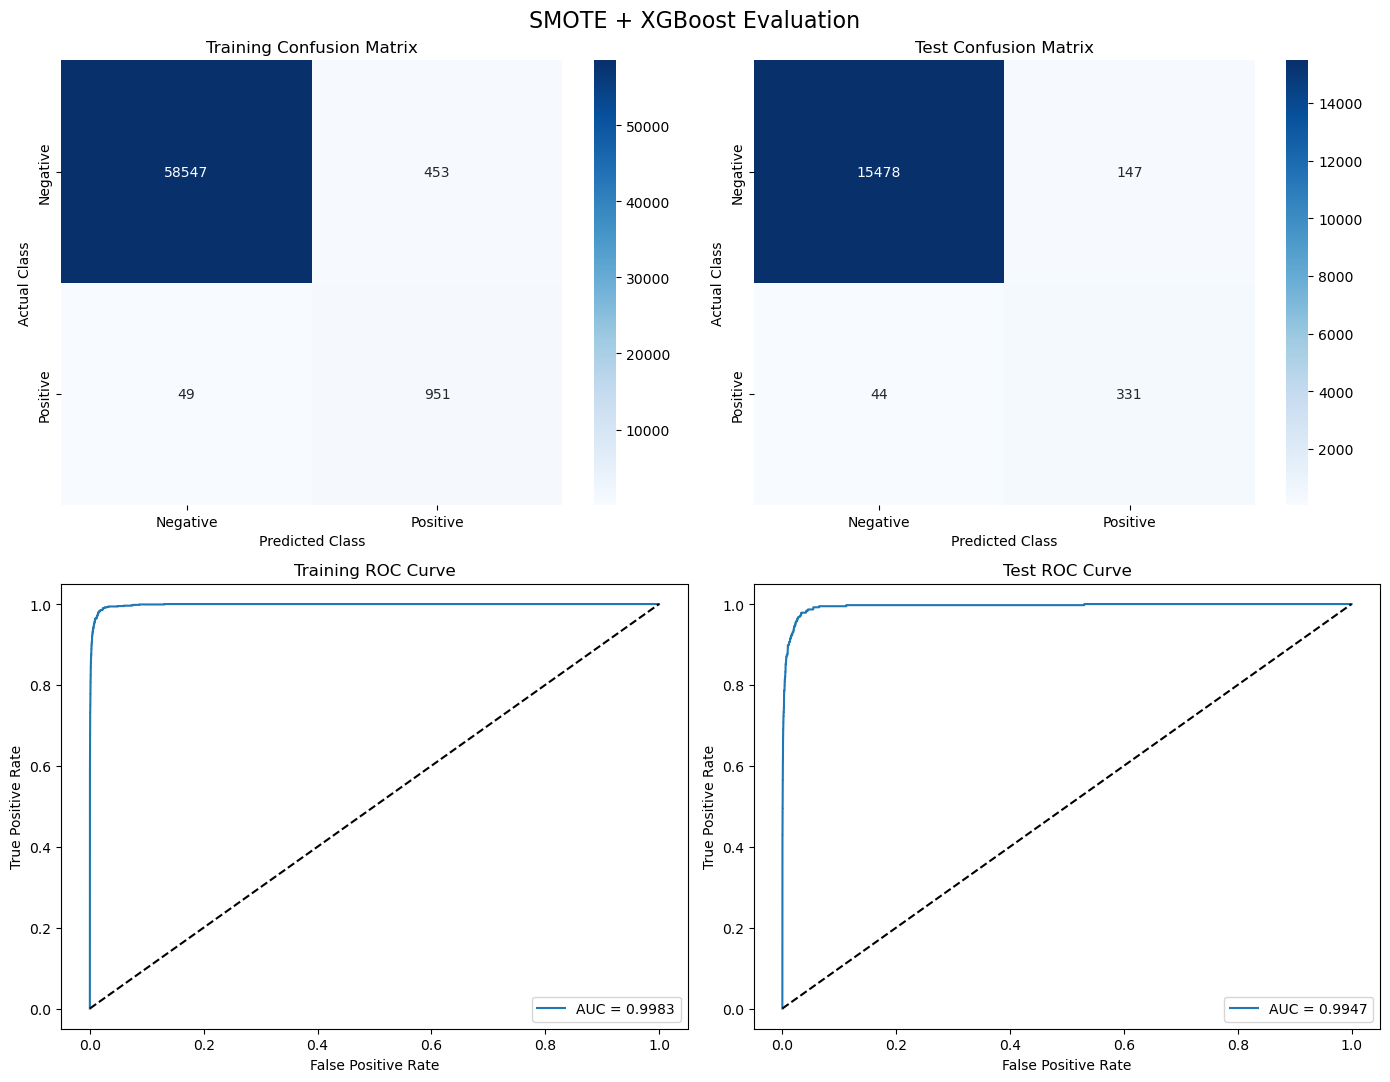

In [45]:
# Question 1(f): SMOTE + XGBoost visualizations

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, cm, title in [
    (axes[0, 0], cm_train_smote, "Training Confusion Matrix"),
    (axes[0, 1], cm_test_smote, "Test Confusion Matrix")
]:
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

for ax, y_true, probs, auc_value, title in [
    (axes[1, 0], y_train, y_train_prob_smote,
     train_auc_smote, "Training ROC Curve"),
    (axes[1, 1], y_test, y_test_prob_smote,
     test_auc_smote, "Test ROC Curve")
]:
    fpr, tpr, _ = roc_curve(y_true, probs)
    ax.plot(fpr, tpr, label=f"AUC = {auc_value:.4f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(title)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

plt.suptitle(
    "SMOTE + XGBoost Evaluation",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [46]:
# Question 1(f): Final SMOTE evaluation summary

print("SMOTE + XGBOOST TRAINING")
print("Confusion Matrix:")
print(cm_train_smote)
print(f"Training Error: {train_error_smote:.6f}")
print(f"Training AUC: {train_auc_smote:.6f}")

print("\nSMOTE + XGBOOST TEST")
print("Confusion Matrix:")
print(cm_test_smote)
print(f"Test Error: {test_error_smote:.6f}")
print(f"Test AUC: {test_auc_smote:.6f}")

tn, fp, fn, tp = cm_test_smote.ravel()

print("\nAPS FAILURE DETECTION")
print("False Positives:", fp)
print("False Negatives:", fn)
print(f"Positive Recall: {tp / (tp + fn):.4f}")

print("\nCROSS-VALIDATION VS TEST")
print(f"CV Error: {cv_error_smote:.6f}")
print(f"Test Error: {test_error_smote:.6f}")
print(f"Difference: {abs(cv_error_smote - test_error_smote):.6f}")

SMOTE + XGBOOST TRAINING
Confusion Matrix:
[[58547   453]
 [   49   951]]
Training Error: 0.008367
Training AUC: 0.998323

SMOTE + XGBOOST TEST
Confusion Matrix:
[[15478   147]
 [   44   331]]
Test Error: 0.011938
Test AUC: 0.994686

APS FAILURE DETECTION
False Positives: 147
False Negatives: 44
Positive Recall: 0.8827

CROSS-VALIDATION VS TEST
CV Error: 0.011083
Test Error: 0.011938
Difference: 0.000854


### Question 1(f): Results and Discussion

SMOTE was applied within a five-fold stratified
cross-validation pipeline to address class imbalance
while preventing data leakage.

Cross-validation selected alpha = 0 for the SMOTE
model, with a CV error of 0.011083.

The SMOTE-based XGBoost model achieved a training
error of 0.008367 and a test error of 0.011938.

The training AUC was 0.998323, while the test AUC
was 0.994686.

The test confusion matrix contained 147 false
positives and 44 false negatives.

Compared with XGBoost without SMOTE, the number
of false negatives decreased from 95 to 44, and
positive-class recall increased from 74.67% to
88.27%.

However, false positives increased from 15 to 147,
and test misclassification error increased from
0.006875 to 0.011938.

Therefore, SMOTE improved minority-class detection
but reduced overall classification accuracy.

This trade-off may be acceptable in applications
where missing an APS-related failure is more costly
than performing an unnecessary inspection.

The CV error of 0.011083 was close to the test
error of 0.011938, with an absolute difference
of 0.000854.

Overall, SMOTE improved APS failure recall, although
it did not improve overall test accuracy or AUC.

**Cost-Sensitive Interpretation:**

According to the APS dataset description, false
positives incur a cost of 10, while false negatives
incur a cost of 500.

Using these costs, the XGBoost model without SMOTE
produced a total misclassification cost of 47,650.

The SMOTE-based model produced a lower cost of 23,470,
representing a reduction of approximately 50.7%.

Therefore, despite its higher overall classification
error, SMOTE may be preferable when the operational
cost of missing APS failures is considered.

## Question 2: ISLR 6.6.3 — Lasso Regression

### Given Optimization Problem

The Lasso regression coefficients are estimated by minimizing:

$$
\min_{\beta_0,\beta_1,\ldots,\beta_p}
\sum_{i=1}^{n}
\left(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\right)^2
$$

subject to the constraint:

$$
\sum_{j=1}^{p}|\beta_j|\leq s
$$

where:

- $n$ is the number of observations.
- $p$ is the number of predictors.
- $\beta_0$ is the intercept.
- $\beta_j$ represents the regression coefficients.
- $s$ controls the strength of the Lasso constraint.

As $s$ increases, the constraint becomes less restrictive,
allowing the model to become more flexible.

### (a) Training RSS

**Correct Answer: (iv) Steadily decrease.**

Training residual sum of squares is defined as:

$$
RSS_{\text{train}}=
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

As $s$ increases, the feasible region for the regression
coefficients becomes larger.

Since the model can select from a larger set of possible
coefficient values, the minimum training RSS cannot
increase.

Therefore, training RSS decreases or remains constant
as $s$ increases.

### (b) Test RSS

**Correct Answer: (ii) Decrease initially, then increase
in a U-shape.**

Test RSS is defined as:

$$
RSS_{\text{test}}=
\sum_{i=1}^{n_{\text{test}}}
(y_i-\hat{y}_i)^2
$$

For small values of $s$, the model is highly constrained
and may underfit the data.

As $s$ increases, model flexibility improves, reducing
bias and typically decreasing test RSS.

However, excessive flexibility may lead to overfitting,
causing test RSS to increase.

Therefore, test RSS typically follows a U-shaped pattern.

### (c) Variance

**Correct Answer: (iii) Steadily increase.**

The variance of a prediction can be expressed as:

$$
\operatorname{Var}(\hat{f}(x))
=
E\left[
(\hat{f}(x)-E[\hat{f}(x)])^2
\right]
$$

When $s$ is small, strong regularization restricts
the regression coefficients and reduces model
sensitivity to the training data.

As $s$ increases, regularization weakens and the
model becomes more flexible.

Consequently, the model generally becomes more
sensitive to variations in the training dataset.

Therefore, variance tends to increase.

### (d) Squared Bias

**Correct Answer: (iv) Steadily decrease.**

Squared bias is defined as:

$$
\operatorname{Bias}(\hat{f}(x))^2
=
\left(E[\hat{f}(x)]-f(x)\right)^2
$$

When $s$ is small, the model is strongly constrained,
which can introduce substantial bias.

Increasing $s$ reduces the restriction on the
regression coefficients.

This allows the model to better approximate the
underlying relationship between predictors and response.

Therefore, squared bias generally decreases as
$s$ increases.

### (e) Irreducible Error

**Correct Answer: (v) Remain constant.**

The irreducible error is:

$$
\operatorname{Var}(\epsilon)=\sigma^2
$$

The expected prediction error can be decomposed as:

$$
E[(Y-\hat{f}(x))^2]
=
\operatorname{Bias}(\hat{f}(x))^2
+
\operatorname{Var}(\hat{f}(x))
+
\sigma^2
$$

Irreducible error represents the inherent randomness
or noise in the data.

It does not depend on the regularization parameter
or the flexibility of the fitted model.

Therefore, irreducible error remains constant.

### Final Answers

| Part | Quantity | Correct Option |
|---|---|---|
| (a) | Training RSS | (iv) |
| (b) | Test RSS | (ii) |
| (c) | Variance | (iii) |
| (d) | Squared Bias | (iv) |
| (e) | Irreducible Error | (v) |

**Conclusion:**

Increasing $s$ weakens the Lasso constraint and increases
model flexibility. Training RSS cannot increase, while
test RSS typically exhibits a U-shaped pattern due to
the bias-variance trade-off.

Variance generally increases, squared bias generally
decreases, and irreducible error remains constant.

## Question 3: ISLR 6.6.5 — Ridge and Lasso Regression

### Given Information

Consider a regression problem with:

$$
n=2,\qquad p=2
$$

The two predictors are perfectly correlated:

$$
x_{11}=x_{12},\qquad x_{21}=x_{22}
$$

The response and predictor values are centered:

$$
y_1+y_2=0
$$

$$
x_{11}+x_{21}=0
$$

$$
x_{12}+x_{22}=0
$$

Therefore, the estimated intercept is:

$$
\hat{\beta}_0=0
$$

Let:

$$
x_{11}=x_{12}=x
$$

Then, because the predictors are centered:

$$
x_{21}=x_{22}=-x
$$

Similarly, let:

$$
y_1=y,\qquad y_2=-y
$$

We use these relationships to derive the ridge and
Lasso optimization problems.

### (a) Ridge Regression Optimization Problem

Ridge regression minimizes:

$$
\sum_{i=1}^{n}
\left(y_i-\beta_0-\sum_{j=1}^{p}
\beta_jx_{ij}\right)^2
+
\lambda\sum_{j=1}^{p}\beta_j^2
$$

Since the intercept is zero and there are two
observations and two predictors:

$$
\begin{aligned}
L_{\text{ridge}}={}&
(y_1-\beta_1x_{11}-\beta_2x_{12})^2\\
&+(y_2-\beta_1x_{21}-\beta_2x_{22})^2\\
&+\lambda(\beta_1^2+\beta_2^2)
\end{aligned}
$$

Using the given relationships:

$$
L_{\text{ridge}}
=
2[y-x(\beta_1+\beta_2)]^2
+
\lambda(\beta_1^2+\beta_2^2)
$$

Therefore, the ridge optimization problem is:

$$
\boxed{
\min_{\beta_1,\beta_2}
2[y-x(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2)
}
$$

### (b) Show That the Ridge Coefficients Are Equal

We want to prove:

$$
\hat{\beta}_1=\hat{\beta}_2
$$

Starting with:

$$
L_{\text{ridge}}
=
2[y-x(\beta_1+\beta_2)]^2
+
\lambda(\beta_1^2+\beta_2^2)
$$

Differentiate with respect to $\beta_1$:

$$
\frac{\partial L}{\partial\beta_1}
=
-4x[y-x(\beta_1+\beta_2)]
+2\lambda\beta_1
$$

Differentiate with respect to $\beta_2$:

$$
\frac{\partial L}{\partial\beta_2}
=
-4x[y-x(\beta_1+\beta_2)]
+2\lambda\beta_2
$$

At the minimum, both derivatives equal zero.

Subtracting the two equations gives:

$$
2\lambda\beta_1-2\lambda\beta_2=0
$$

Therefore:

$$
2\lambda(\beta_1-\beta_2)=0
$$

For $\lambda>0$:

$$
\boxed{\hat{\beta}_1=\hat{\beta}_2}
$$

To find their common value, let:

$$
\beta_1=\beta_2=b
$$

Substituting into the first-order condition:

$$
-4x(y-2xb)+2\lambda b=0
$$

Simplifying:

$$
(8x^2+2\lambda)b=4xy
$$

Hence:

$$
\boxed{
\hat{\beta}_1=\hat{\beta}_2
=\frac{2xy}{4x^2+\lambda}
}
$$

**Conclusion:**

Ridge regression assigns equal coefficients to
identical predictors because its L2 penalty favors
an equal distribution of coefficient magnitudes.

### (c) Lasso Regression Optimization Problem

Lasso regression minimizes:

$$
\sum_{i=1}^{n}
\left(y_i-\beta_0-\sum_{j=1}^{p}
\beta_jx_{ij}\right)^2
+
\lambda\sum_{j=1}^{p}|\beta_j|
$$

Using the given conditions:

$$
L_{\text{lasso}}
=
(y-x(\beta_1+\beta_2))^2
+
(-y+x(\beta_1+\beta_2))^2
+
\lambda(|\beta_1|+|\beta_2|)
$$

The first two terms are identical after squaring.

Therefore:

$$
\boxed{
\min_{\beta_1,\beta_2}
2[y-x(\beta_1+\beta_2)]^2
+
\lambda(|\beta_1|+|\beta_2|)
}
$$

This is the required Lasso optimization problem.

### (d) Show That Lasso Coefficients Are Not Unique

Unlike ridge regression, Lasso does not necessarily
assign equal coefficients to perfectly correlated
predictors.

Define:

$$
t=\beta_1+\beta_2
$$

The Lasso objective becomes:

$$
L_{\text{lasso}}
=
2(y-xt)^2+\lambda(|\beta_1|+|\beta_2|)
$$

By the triangle inequality:

$$
|\beta_1|+|\beta_2|
\geq|\beta_1+\beta_2|
=|t|
$$

Equality holds when $\beta_1$ and $\beta_2$
have the same sign or one coefficient is zero.

Therefore, the optimization can be reduced to:

$$
\min_t 2(y-xt)^2+\lambda|t|
$$

For $x\neq0$, its solution is:

$$
\boxed{
t^*=
\frac{\operatorname{sign}(xy)
\max(|xy|-\lambda/4,0)}{x^2}
}
$$

When $t^*>0$, every pair satisfying:

$$
\beta_1\geq0,\qquad\beta_2\geq0
$$

and

$$
\beta_1+\beta_2=t^*
$$

is an optimal solution.

For example:

$$
(\beta_1,\beta_2)=(t^*,0)
$$

$$
(\beta_1,\beta_2)=(0,t^*)
$$

$$
(\beta_1,\beta_2)=(t^*/2,t^*/2)
$$

all produce the same objective value.

When $t^*<0$, any pair of nonpositive coefficients
whose sum is $t^*$ is also optimal.

When $t^*=0$, the unique optimal pair is $(0,0)$.

Therefore, when the optimal sum is nonzero, infinitely
many coefficient pairs minimize the Lasso objective.

**Conclusion:**

Lasso coefficients are not necessarily unique when
predictors are perfectly correlated.

Lasso can distribute the total coefficient across
identical predictors in multiple ways without
changing the fitted values or the L1 penalty.

Ridge regression, by contrast, produces equal
coefficients for identical predictors when
$\lambda>0$.

### Final Summary

| Part | Result |
|---|---|
| (a) | Derive the ridge optimization objective |
| (b) | Ridge gives equal coefficients |
| (c) | Derive the Lasso optimization objective |
| (d) | Lasso can have infinitely many optimal coefficient pairs |

The key difference is that ridge regression tends
to share coefficient weights among correlated
predictors, while Lasso can produce non-unique
solutions when predictors are identical.

## Question 4: ISLR 8.4.5 — Bagging Classification

### Given Information

Ten bootstrap samples are generated from a dataset
containing Red and Green observations.

A classification tree is fitted to each bootstrap sample.

For a particular observation X, the estimated probabilities
of belonging to the Red class are:

$$
0.10,\ 0.15,\ 0.20,\ 0.20,\ 0.55,\ 0.60,\
0.60,\ 0.65,\ 0.70,\ 0.75
$$

We compare majority voting and average probability
classification.

### (a) Majority Voting

Under majority voting, each tree independently predicts
a class.

The classification rule is:

$$
\hat{C}_b(X)=
\begin{cases}
\text{Red}, & \hat{P}_b(\text{Red}\mid X)>0.5\\
\text{Green}, & \text{otherwise}
\end{cases}
$$

The first four probabilities are below 0.5, so four
trees predict Green.

The remaining six probabilities are above 0.5,
so six trees predict Red.

Therefore:

$$
N_{\text{Red}}=6
$$

$$
N_{\text{Green}}=4
$$

Since six out of ten trees predict Red:

$$
\boxed{\text{Majority Vote Prediction = Red}}
$$

### (b) Average Probability Classification

Under this method, we calculate the average predicted
probability across all ten trees.

The formula is:

$$
\bar{P}(\text{Red}\mid X)
=
\frac{1}{B}\sum_{b=1}^{B}
\hat{P}_b(\text{Red}\mid X)
$$

where B = 10.

Substituting the given probabilities:

$$
\begin{aligned}
\bar{P}(\text{Red}\mid X)
=\frac{1}{10}(&0.10+0.15+0.20+0.20\\
&+0.55+0.60+0.60+0.65\\
&+0.70+0.75)
\end{aligned}
$$

$$
=\frac{4.50}{10}=0.45
$$

Since:

$$
0.45<0.50
$$

the average probability method predicts Green.

$$
\boxed{\text{Average Probability Prediction = Green}}
$$

### Final Comparison

| Method | Result |
|---|---|
| Majority Voting | Red |
| Average Probability | Green |

### Conclusion

The two aggregation methods produce different predictions.

Majority voting predicts Red because six of the ten
classification trees individually predict Red.

Average probability classification predicts Green
because the average probability of Red is only 0.45.

This difference occurs because majority voting counts
class decisions, whereas probability averaging considers
the magnitude of each tree's predicted probability.

Therefore, the two bagging aggregation methods do not
necessarily produce identical classifications.

## Question 5: ISLR 9.7.3 — Maximal Margin Classifier

### Given Information

We are given seven observations with two predictors,
$X_1$ and $X_2$, and a binary class label (Red or Blue).

| Observation | X1 | X2 | Class |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

The objective is to determine the maximal margin
separating hyperplane, its classification rule,
margin, and support vectors.

---

### (a) Sketch the Observations

The seven observations are plotted in a two-dimensional
coordinate system with $X_1$ on the horizontal axis
and $X_2$ on the vertical axis.

Red observations:

$$
(3,4),\ (2,2),\ (4,4),\ (1,4)
$$

Blue observations:

$$
(2,1),\ (4,3),\ (4,1)
$$

The scatter plot below illustrates the observations
using red and blue markers.

The classes are linearly separable because a straight
line can separate all Red observations from all Blue
observations.

### (b) Optimal Separating Hyperplane

A separating hyperplane in two dimensions is defined by:

$$
\beta_0+\beta_1X_1+\beta_2X_2=0
$$

The maximal margin classifier selects the hyperplane
that maximizes the minimum perpendicular distance
between the separating line and the training observations.

For this dataset, the optimal separating hyperplane is:

$$
\boxed{X_2=X_1-0.5}
$$

Equivalently:

$$
\boxed{0.5-X_1+X_2=0}
$$

The line lies halfway between the parallel lines:

$$
X_2=X_1
$$

and

$$
X_2=X_1-1
$$

The first line contains the nearest Red observations,
while the second contains the nearest Blue observations.

Therefore, the optimal hyperplane is centered between
the closest observations from the two classes.

### (c) Classification Rule

The classification function is:

$$
f(X)=\beta_0+\beta_1X_1+\beta_2X_2
$$

For the optimal separating hyperplane, we choose:

$$
\boxed{
\beta_0=0.5,\quad
\beta_1=-1,\quad
\beta_2=1
}
$$

Thus:

$$
f(X)=0.5-X_1+X_2
$$

The classification rule is:

$$
\boxed{
\hat{Y}=
\begin{cases}
\text{Red}, & 0.5-X_1+X_2>0\\
\text{Blue}, & 0.5-X_1+X_2<0
\end{cases}
}
$$

Points exactly on the separating hyperplane have
$f(X)=0$ and require a tie-breaking convention.

For example, observation 2 is located at $(2,2)$:

$$
f(2,2)=0.5-2+2=0.5>0
$$

Therefore, observation 2 is classified as Red.

For observation 5 at $(2,1)$:

$$
f(2,1)=0.5-2+1=-0.5<0
$$

Therefore, observation 5 is classified as Blue.

### (d) Margin of the Maximal Margin Hyperplane

The margin is the perpendicular distance between
the optimal separating hyperplane and its closest
training observations.

For a hyperplane:

$$
\beta_0+\beta_1X_1+\beta_2X_2=0
$$

the perpendicular distance from a point to the
hyperplane is:

$$
d(X)=
\frac{
|\beta_0+\beta_1X_1+\beta_2X_2|
}{
\sqrt{\beta_1^2+\beta_2^2}
}
$$

For the optimal hyperplane:

$$
0.5-X_1+X_2=0
$$

we have:

$$
\beta_1=-1,\qquad\beta_2=1
$$

For the closest observations, the absolute
decision-function value is 0.5.

Therefore:

$$
M=\frac{0.5}{\sqrt{(-1)^2+1^2}}
$$

$$
M=\frac{0.5}{\sqrt{2}}
$$

$$
\boxed{M\approx0.3536}
$$

This is the geometric margin on each side.

The total distance between the two supporting
hyperplanes is:

$$
2M=\frac{1}{\sqrt{2}}
$$

$$
\boxed{2M\approx0.7071}
$$

The margin boundaries are:

$$
\boxed{X_2=X_1}
$$

and

$$
\boxed{X_2=X_1-1}
$$

### (e) Identify the Support Vectors

Support vectors are observations lying closest to
the optimal separating hyperplane.

For this dataset, the support vectors are:

| Observation | X1 | X2 | Class |
|---|---|---|---|
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |

Observations 2 and 3 lie on:

$$
X_2=X_1
$$

Observations 5 and 6 lie on:

$$
X_2=X_1-1
$$

All four observations have the same perpendicular
distance from the optimal separating hyperplane.

Therefore:

$$
\boxed{
\text{Support Vectors}=\{2,3,5,6\}
}
$$

These observations determine the position and
orientation of the maximal margin hyperplane.

### (f) Effect of Moving the Seventh Observation

Observation 7 is located at:

$$
(X_1,X_2)=(4,1)
$$

and belongs to the Blue class.

Its perpendicular distance from the hyperplane is:

$$
d_7=
\frac{|0.5-4+1|}{\sqrt{2}}
$$

$$
d_7=\frac{2.5}{\sqrt{2}}
$$

$$
\boxed{d_7\approx1.7678}
$$

Since:

$$
1.7678>0.3536
$$

observation 7 is not a support vector.

A sufficiently small movement of observation 7
that keeps it outside the margin will not change
the maximal margin hyperplane.

This is because the hyperplane is determined by
the closest observations, namely the support vectors.

Therefore, slight movement of observation 7 does
not affect the optimal separating hyperplane.

### (g) Non-Optimal Separating Hyperplane

A possible separating hyperplane that is not
optimal is:

$$
\boxed{X_2=X_1-0.25}
$$

Equivalently:

$$
\boxed{0.25-X_1+X_2=0}
$$

For the Red support vectors, where $X_2=X_1$:

$$
f(X)=0.25>0
$$

For the Blue support vectors, where $X_2=X_1-1$:

$$
f(X)=-0.75<0
$$

Therefore, this hyperplane correctly separates
all the observations.

However, its minimum perpendicular distance
to the training observations is:

$$
M_{\text{alternative}}
=
\frac{0.25}{\sqrt{2}}
$$

$$
\boxed{M_{\text{alternative}}\approx0.1768}
$$

Since:

$$
0.1768<0.3536
$$

this hyperplane has a smaller margin than the
optimal separating hyperplane.

Therefore, it is a valid separating hyperplane,
but it is not the maximal margin hyperplane.

### (h) Add an Observation That Prevents Linear Separation

Consider adding a new Blue observation at:

$$
\boxed{(X_1,X_2)=(3,3)}
$$

This observation lies on the line segment between
two existing Red observations:

$$
(2,2)\quad\text{and}\quad(4,4)
$$

Specifically:

$$
(3,3)=\frac{1}{2}(2,2)+\frac{1}{2}(4,4)
$$

Therefore, the new Blue observation lies inside
the convex hull of the Red observations.

A linear classifier cannot assign positive
decision-function values to both endpoints of
this line segment while assigning a negative
value to their midpoint.

Consequently, no linear hyperplane can perfectly
separate the Red and Blue observations.

Thus, the dataset becomes non-linearly separable.

### Final Conclusion

The maximal margin classifier identifies the
separating hyperplane that maximizes the minimum
distance to the training observations.

The optimal separating hyperplane is:

$$
\boxed{X_2=X_1-0.5}
$$

Equivalently:

$$
\boxed{0.5-X_1+X_2=0}
$$

The classification coefficients are:

$$
\boxed{
\beta_0=0.5,\quad
\beta_1=-1,\quad
\beta_2=1
}
$$

The geometric margin on each side is:

$$
\boxed{M\approx0.3536}
$$

The support vectors are observations:

$$
\boxed{\{2,3,5,6\}}
$$

A sufficiently small movement of observation 7
does not affect the optimal hyperplane because
it is not a support vector.

The alternative hyperplane:

$$
X_2=X_1-0.25
$$

correctly separates the classes but has a
smaller margin.

Finally, adding a Blue observation at $(3,3)$
makes the classes no longer linearly separable.

These results demonstrate the importance of
support vectors and margin maximization in
support vector classification.

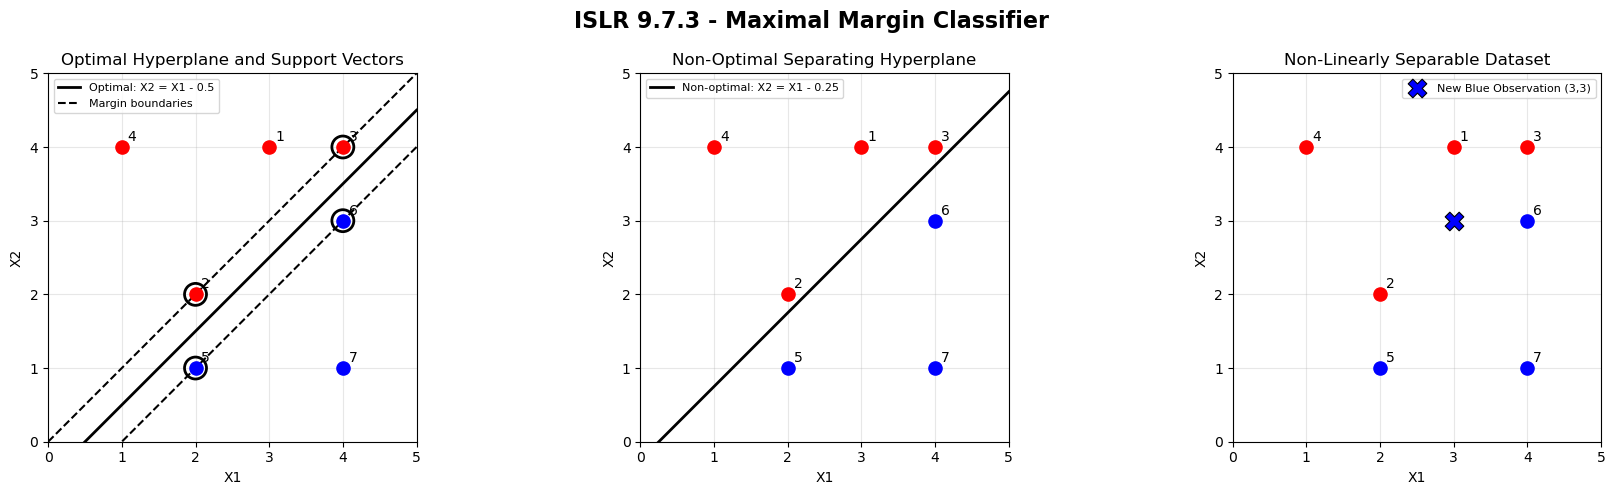

Classification verification:
Observation 1: Actual=Red, Predicted=Red
Observation 2: Actual=Red, Predicted=Red
Observation 3: Actual=Red, Predicted=Red
Observation 4: Actual=Red, Predicted=Red
Observation 5: Actual=Blue, Predicted=Blue
Observation 6: Actual=Blue, Predicted=Blue
Observation 7: Actual=Blue, Predicted=Blue

Geometric margin: 0.353553
Total margin width: 0.707107
Support vectors: 2, 3, 5, 6


In [47]:
# Question 5: ISLR 9.7.3
# Maximal Margin Classifier 

import numpy as np
import matplotlib.pyplot as plt

# Original observations
X = np.array([
    [3, 4],
    [2, 2],
    [4, 4],
    [1, 4],
    [2, 1],
    [4, 3],
    [4, 1]
])

labels = np.array([
    "Red", "Red", "Red", "Red",
    "Blue", "Blue", "Blue"
])

# Coordinates for separating lines
x = np.linspace(0, 5, 300)

# optimal hyperplane
optimal_line = x - 0.5

# margin boundaries
upper_margin = x
lower_margin = x - 1

# Create three plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

def plot_points(ax):
    for i, (point, label) in enumerate(zip(X, labels)):
        color = "red" if label == "Red" else "blue"

        ax.scatter(
            point[0],
            point[1],
            color=color,
            s=90,
            zorder=3
        )

        ax.annotate(
            str(i + 1),
            (point[0] + 0.08, point[1] + 0.08)
        )

    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(alpha=0.3)

# Plot 1: Optimal hyperplane and support vectors
plot_points(axes[0])

axes[0].plot(
    x, optimal_line,
    "k-",
    linewidth=2,
    label="Optimal: X2 = X1 - 0.5"
)

axes[0].plot(
    x, upper_margin,
    "k--",
    label="Margin boundaries"
)

axes[0].plot(
    x, lower_margin,
    "k--"
)

# Support vectors: observations 2, 3, 5, 6
support_indices = [1, 2, 4, 5]

for i in support_indices:
    axes[0].scatter(
        X[i, 0],
        X[i, 1],
        s=250,
        facecolors="none",
        edgecolors="black",
        linewidths=2,
        zorder=4
    )

axes[0].set_title(
    "Optimal Hyperplane and Support Vectors"
)
axes[0].legend(fontsize=8)

# Plot 2: Non-optimal separating hyperplane
plot_points(axes[1])

axes[1].plot(
    x,
    x - 0.25,
    "k-",
    linewidth=2,
    label="Non-optimal: X2 = X1 - 0.25"
)

axes[1].set_title(
    "Non-Optimal Separating Hyperplane"
)
axes[1].legend(fontsize=8)

# Plot 3: Non-linearly separable dataset
plot_points(axes[2])

axes[2].scatter(
    3,
    3,
    color="blue",
    s=180,
    marker="X",
    edgecolors="black",
    linewidths=0.8,
    zorder=5,
    label="New Blue Observation (3,3)"
)

axes[2].set_title(
    "Non-Linearly Separable Dataset"
)
axes[2].legend(fontsize=8)

plt.suptitle(
    "ISLR 9.7.3 - Maximal Margin Classifier",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Verify the optimal separating hyperplane
decision_values = 0.5 - X[:, 0] + X[:, 1]

print("Classification verification:")
for i, value in enumerate(decision_values):
    predicted = "Red" if value > 0 else "Blue"
    print(
        f"Observation {i+1}: "
        f"Actual={labels[i]}, Predicted={predicted}"
    )

# Verify margin
margin = 0.5 / np.sqrt(2)

print(f"\nGeometric margin: {margin:.6f}")
print(f"Total margin width: {2 * margin:.6f}")
print("Support vectors: 2, 3, 5, 6")